# Beyond Words — Notebook 04: Condition C (HingRoBERTa, English-only task training)

**Research project:** Beyond Words — Cross-lingual Emotion and Sarcasm Analysis in Romanized Hinglish
**Notebook role:** Experimental Condition C — HingRoBERTa backbone, English-only GoEmotions training
**Derived from:** `03_english_emotion_baseline.ipynb` (Condition A). The data checks, training loop, evaluation, calibration, error analysis and aggregation code is carried over from that notebook unchanged. Only the items in the table below differ.

| Condition | Backbone | Task-training data |
|---|---|---|
| A | XLM-R | English only |
| B | XLM-R | English + Hinglish |
| **C (this notebook)** | **HingRoBERTa** | **English only** |
| D | HingRoBERTa | English + Hinglish |

## What changed relative to Condition A

| Item | Condition A | Condition C |
|---|---|---|
| Backbone | `FacebookAI/xlm-roberta-base` | `l3cube-pune/hing-roberta`, pinned to a fixed Hub revision |
| `experiment_name` / `condition_label` | `xlmr_english_ekman7` / `A` | `hingroberta_english_ekman7` / `C` |
| Output folders | `outputs/english_emotion`, `models/english_emotion` | `outputs/english_emotion_condC`, `models/english_emotion_condC` (A's files are never overwritten) |
| Added checks | — | Hyper-parameter freeze check, split-identity check against A's saved logits, tokenizer/architecture comparison with XLM-R, 20-step smoke test |
| Added utilities | — | Per-seed resume, rebuild-from-disk aggregation, per-class tables, A-vs-C paired comparison (Section 23) |

## What must not change

Dataset file, label order, splits, seeds, learning rate, batch size, epochs, warm-up, weight decay, gradient clipping, class-weighted loss, checkpoint rule (validation macro-F1) and the rule that the test set is evaluated once per seed. Section 4b enforces the hyper-parameters with an assertion.

## Interpretation notes

- HingRoBERTa is already pre-trained on Romanized Hinglish text. "English-only" in Condition C refers to the **task-training data**, not to the backbone. The Hub model is tagged `xlm-roberta`; Section 10b checks its architecture and tokenizer against XLM-R rather than assuming they match.
- On the English GoEmotions test set, A vs C measures what Hinglish-oriented pre-training does to English emotion performance. It says nothing yet about Hinglish transfer. That needs the Hinglish test sets.
- The model is licensed CC-BY-4.0. Cite Nayak & Joshi (2022), *L3Cube-HingCorpus and HingBERT*.
- The weights ship as a pickle-based `pytorch_model.bin`. Load them only from the official repository at the pinned revision, with the pinned `transformers` version.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Section 1 — Installation

Package versions are pinned to the ones used for Condition A (`transformers==4.48.3`, `tokenizers==0.21.0`). **Restart the runtime after this cell**, then continue from Section 2. Compare the versions printed in Section 8b with Condition A's `experiment_metadata.json`.


In [1]:
import subprocess, sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir",
         "transformers==4.48.3", "tokenizers==0.21.0", "sentencepiece",
         "accelerate>=1.2.0", "scikit-learn>=1.4.0", "seaborn>=0.13.0", "scipy>=1.12.0"],
        check=True,
    )
    print("Packages installed. RESTART THE RUNTIME NOW, then run from Section 2.")
else:
    print("Not in Colab: install transformers==4.48.3 tokenizers==0.21.0 sentencepiece "
          "accelerate scikit-learn seaborn scipy pandas numpy matplotlib in your environment.")


Packages installed. RESTART THE RUNTIME NOW, then run from Section 2.


## Section 2 — Imports

All imports are gathered in one cell so the notebook fails fast if a package is missing.  
`TOKENIZERS_PARALLELISM=false` suppresses a benign Hugging Face warning about forked processes.


In [2]:
# Standard library
import datetime
import json
import os
import platform
import random
import sys
import time
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple

warnings.filterwarnings("ignore", category=UserWarning)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Scientific stack
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax as scipy_softmax

# scikit-learn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Hugging Face Transformers
import transformers
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Platform     : {platform.platform()}")
print(f"In Colab     : {IN_COLAB}")


Python       : 3.13.16
PyTorch      : 2.14.1+cu130
Transformers : 4.48.3
NumPy        : 2.4.6
Pandas       : 2.2.3
Platform     : Linux-6.6.159+-x86_64-with-glibc2.39
In Colab     : True


## Section 3 — Project paths and directory setup

The project root is `/content/Beyond-Words/` on Google Colab.  
All outputs are written to well-defined subdirectories so raw data is never overwritten.

**Directory layout:**

```
Beyond-Words/
├── data/
│   └── processed/
│       └── goemotions_ekman_dedup.csv   ← frozen; never overwritten
├── models/
│   └── english_emotion_condC/
│       ├── seed_42/
│       ├── seed_123/
│       └── seed_2026/
├── outputs/
│   └── english_emotion_condC/
│       ├── predictions/
│       ├── metrics/
│       ├── logits/
│       ├── figures/
│       └── logs/
└── configs/
    └── english_emotion_condC_config.json
```


In [3]:
# ── Project root ─────────────────────────────────────────────────────────
try:
    import google.colab  # noqa: F401
    PROJECT_ROOT = Path("/content/Beyond-Words")
except ImportError:
    # Local: assume notebook is in notebooks/, project root is one level up
    PROJECT_ROOT = Path(__file__).resolve().parent.parent if "__file__" in dir() else Path.cwd().parent

# ── Directory map ─────────────────────────────────────────────────────────
DIRS = {
    "data_processed" : PROJECT_ROOT / "data" / "processed",
    "data_raw"       : PROJECT_ROOT / "data" / "raw",
    "data_interim"   : PROJECT_ROOT / "data" / "interim",
    "models_root"    : PROJECT_ROOT / "models" / "english_emotion_condC",
    "out_predictions": PROJECT_ROOT / "outputs" / "english_emotion_condC" / "predictions",
    "out_metrics"    : PROJECT_ROOT / "outputs" / "english_emotion_condC" / "metrics",
    "out_logits"     : PROJECT_ROOT / "outputs" / "english_emotion_condC" / "logits",
    "out_figures"    : PROJECT_ROOT / "outputs" / "english_emotion_condC" / "figures",
    "out_logs"       : PROJECT_ROOT / "outputs" / "english_emotion_condC" / "logs",
    "configs"        : PROJECT_ROOT / "configs",
}

for name, path in DIRS.items():
    path.mkdir(parents=True, exist_ok=True)

DATASET_PATH = DIRS["data_processed"] / "goemotions_ekman_dedup.csv"

# Restore the frozen dataset from Drive if it is not in this runtime (GoEmotions is public data).
if not DATASET_PATH.exists():
    try:
        import shutil
        from google.colab import drive
        drive.mount("/content/drive")
        _drive_csv = Path("/content/drive/MyDrive/Beyond-Words/data/processed/goemotions_ekman_dedup.csv")
        if _drive_csv.exists():
            shutil.copy2(_drive_csv, DATASET_PATH)
            print("Restored dataset from Drive:", _drive_csv)
    except Exception as _e:
        print("Drive restore skipped:", repr(_e)[:120])

print(f"Project root   : {PROJECT_ROOT}")
print(f"Dataset path   : {DATASET_PATH}")
print(f"Dataset exists : {DATASET_PATH.exists()}")

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"\n\n❌  Dataset not found at: {DATASET_PATH}\n"
        "Please upload goemotions_ekman_dedup.csv to data/processed/ "
        "before running this notebook.\n"
        "Do NOT replace it with a different CSV — this dataset is frozen by the "
        "preprocessing pipeline in notebook 01_dataset_exploration.ipynb."
    )

print("\n✅  All directories created. Dataset located.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Restored dataset from Drive: /content/drive/MyDrive/Beyond-Words/data/processed/goemotions_ekman_dedup.csv
Project root   : /content/Beyond-Words
Dataset path   : /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv
Dataset exists : True

✅  All directories created. Dataset located.


## Section 4 — Experiment configuration

All hyperparameters, model choices, and flags live in a single `CFG` dictionary.

### Why centralise configuration?

Changing `MODEL_NAME` from `"FacebookAI/xlm-roberta-base"` to `"l3cube-pune/hing-roberta"` (HingRoBERTa) will make the **entire notebook** adapt — tokeniser, model, checkpoint naming — without touching any implementation cell. This is the backbone-agnostic design.

### Why these initial hyperparameter values?

| Parameter | Value | Rationale |
|---|---|---|
| Learning rate | 2e-5 | Standard for fine-tuning pre-trained transformers; too high risks destroying pre-trained representations |
| Epochs | 3 | GoEmotions is large (~39k train); 3 epochs is sufficient and avoids overfitting |
| Batch size | 16 | Fits T4 VRAM (~15 GB) with XLM-R-base at max_seq_len 128; reduce to 8 if OOM |
| max_seq_len | 128 | We will verify empirically that this covers ≥95% of GoEmotions texts |
| Warmup ratio | 0.1 | Linearly ramp LR for the first 10% of steps — prevents corrupting pre-trained weights early |
| Weight decay | 0.01 | L2 regularisation on non-bias/non-LayerNorm parameters |
| Gradient clipping | 1.0 | Prevents exploding gradients, especially in early fine-tuning |
| Seeds | [42, 123, 2026] | Three independent runs to estimate variability |


In [4]:
# ── Frozen label mapping (must not change across any experimental condition) ──
LABEL_ORDER = ["anger", "disgust", "fear", "joy", "sadness", "surprise", "neutral"]
ID2LABEL    = {i: lbl for i, lbl in enumerate(LABEL_ORDER)}
LABEL2ID    = {lbl: i for i, lbl in enumerate(LABEL_ORDER)}
NUM_LABELS  = len(LABEL_ORDER)

# ── Central experiment configuration ─────────────────────────────────────
CFG = {
    # --- Model (backbone-agnostic: change this one string to switch backbone) ---
    "model_name"          : "l3cube-pune/hing-roberta",
    "model_revision"      : "f714c4bdce6b008a2fbb84193eee99e651c59e15",   # pinned Hub commit (set None to use main; then record the hash from Section 10b)
    "num_labels"          : NUM_LABELS,

    # --- Data ---
    "max_seq_len"         : 128,
    "dataset_path"        : str(DATASET_PATH),

    # --- Training ---
    "num_epochs"          : 3,
    "train_batch_size"    : 16,
    "eval_batch_size"     : 32,
    "learning_rate"       : 2e-5,
    "weight_decay"        : 0.01,
    "warmup_ratio"        : 0.1,
    "grad_clip"           : 1.0,
    "grad_accum_steps"    : 1,     # Increase if OOM: effective_batch = train_batch * grad_accum
    "use_fp16"            : True,  # Mixed precision; auto-disabled if no CUDA
    "use_class_weights"   : True,  # Set False for unweighted ablation

    # --- Experiment control ---
    "seeds"               : [42, 123, 2026],
    "primary_metric"      : "macro_f1",

    # --- Naming ---
    "experiment_name"     : "hingroberta_english_ekman7",
    "condition_label"     : "C",
}

# Save config to disk for reproducibility
config_path = DIRS["configs"] / "english_emotion_condC_config.json"
with open(config_path, "w") as f:
    json.dump(
        {**CFG, "label_order": LABEL_ORDER, "id2label": ID2LABEL, "label2id": LABEL2ID},
        f, indent=2,
    )

print("Experiment configuration:")
for k, v in CFG.items():
    print(f"  {k:<26} = {v}")
print(f"\nConfig saved: {config_path}")


Experiment configuration:
  model_name                 = l3cube-pune/hing-roberta
  model_revision             = f714c4bdce6b008a2fbb84193eee99e651c59e15
  num_labels                 = 7
  max_seq_len                = 128
  dataset_path               = /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv
  num_epochs                 = 3
  train_batch_size           = 16
  eval_batch_size            = 32
  learning_rate              = 2e-05
  weight_decay               = 0.01
  warmup_ratio               = 0.1
  grad_clip                  = 1.0
  grad_accum_steps           = 1
  use_fp16                   = True
  use_class_weights          = True
  seeds                      = [42, 123, 2026]
  primary_metric             = macro_f1
  experiment_name            = hingroberta_english_ekman7
  condition_label            = C

Config saved: /content/Beyond-Words/configs/english_emotion_condC_config.json


## Section 4b — Controlled-variable check

Condition C must use exactly Condition A's training settings. This cell compares the live `CFG` with A's frozen values and stops if anything differs. If you hit an out-of-memory error, halve `train_batch_size` and double `grad_accum_steps` so the effective batch stays 16, and record that deviation in the paper. Do the same for A if you re-run it.


In [5]:
A_FROZEN = {
    "num_labels"       : 7,
    "max_seq_len"      : 128,
    "num_epochs"       : 3,
    "eval_batch_size"  : 32,
    "learning_rate"    : 2e-5,
    "weight_decay"     : 0.01,
    "warmup_ratio"     : 0.1,
    "grad_clip"        : 1.0,
    "use_class_weights": True,
    "seeds"            : [42, 123, 2026],
    "primary_metric"   : "macro_f1",
}
_diff = {k: {"C": CFG[k], "A": v} for k, v in A_FROZEN.items() if CFG[k] != v}
_eff_batch = CFG["train_batch_size"] * CFG["grad_accum_steps"]

print("Effective train batch size:", _eff_batch, "(Condition A: 16)")
print("fp16 flag                 :", CFG["use_fp16"], "(Condition A: True)")
if _diff:
    raise RuntimeError(f"CFG differs from Condition A: {json.dumps(_diff, indent=2)}")
if _eff_batch != 16:
    raise RuntimeError(f"Effective batch {_eff_batch} != 16 (Condition A).")
print("CFG matches Condition A on every controlled hyper-parameter.")
print("Only the backbone, revision, experiment_name and condition_label differ.")


Effective train batch size: 16 (Condition A: 16)
fp16 flag                 : True (Condition A: True)
CFG matches Condition A on every controlled hyper-parameter.
Only the backbone, revision, experiment_name and condition_label differ.


## Section 5 — GPU and environment inspection

### Why check the GPU first?

Google Colab's free T4 GPU has ~15 GB VRAM. Training XLM-R-base at batch size 16 uses approximately 7–9 GB. If CUDA is unavailable, training falls back to CPU, which is ~50× slower — one epoch may take several hours instead of ~12 minutes.

### Mixed precision (FP16)

Instead of storing all weights and activations as 32-bit floats, FP16 uses 16-bit floats for most operations. This approximately:
- Halves VRAM consumption
- Speeds up computation via NVIDIA Tensor Cores

PyTorch's `torch.cuda.amp.autocast()` context manager handles FP16 automatically and falls back to FP32 for numerically sensitive operations (e.g., softmax).

### Recovery if CUDA out-of-memory (OOM)

If you encounter a CUDA OOM error:
1. Reduce `CFG["train_batch_size"]` from 16 → 8
2. Increase `CFG["grad_accum_steps"]` from 1 → 2 (keeps effective batch = 16)
3. Reduce `CFG["max_seq_len"]` from 128 → 96
4. Restart the runtime and re-run from the top

Do not silently change these settings mid-run — document any deviation.


In [6]:
print("=" * 60)
print("ENVIRONMENT INSPECTION")
print("=" * 60)

CUDA_AVAILABLE = torch.cuda.is_available()

if CUDA_AVAILABLE:
    DEVICE     = torch.device("cuda")
    gpu_name   = torch.cuda.get_device_name(0)
    gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"✅  CUDA available")
    print(f"   GPU model  : {gpu_name}")
    print(f"   VRAM total : {gpu_mem_gb:.1f} GB")
    print(f"   Mixed prec : {'FP16 enabled' if CFG['use_fp16'] else 'disabled (CFG override)'}")
else:
    DEVICE = torch.device("cpu")
    CFG["use_fp16"] = False   # FP16 requires CUDA
    print("⚠️  CUDA not available — training on CPU.")
    print("   FP16 disabled automatically.")
    print("   WARNING: CPU training is ~50× slower than T4 GPU.")

print(f"\n   Selected device  : {DEVICE}")
print(f"   PyTorch version  : {torch.__version__}")
print(f"   Transformers     : {transformers.__version__}")
print(f"   Python           : {sys.version.split()[0]}")
print("=" * 60)


ENVIRONMENT INSPECTION
✅  CUDA available
   GPU model  : Tesla T4
   VRAM total : 15.6 GB
   Mixed prec : FP16 enabled

   Selected device  : cuda
   PyTorch version  : 2.14.1+cu130
   Transformers     : 4.48.3
   Python           : 3.13.16


## Section 6 — Reproducibility utilities

### Why fix random seeds?

Neural network training involves many sources of randomness:
- **Weight initialisation** — the classification head starts from random values
- **Data-loading order** — the training DataLoader shuffles examples each epoch
- **Dropout** — randomly zeros activations during training
- **CUDA kernel non-determinism** — some GPU operations are non-deterministic by default

Fixing a seed makes **one specific run** reproducible. Different seeds will — and should — produce slightly different results. That is precisely why we run three seeds: to quantify variability rather than hide it behind a single lucky run.

### Performance note

`torch.backends.cudnn.deterministic = True` disables some highly-optimised but non-deterministic CUDA kernels. This can slow training by 10–30%. This trade-off is acceptable for research reproducibility.


In [7]:
def set_seed(seed: int) -> None:
    """Set all random seeds for reproducibility.

    Parameters
    ----------
    seed : int
        Seed value applied to Python, NumPy, PyTorch CPU, and PyTorch CUDA.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"🌱  Random seed set to {seed}")

# Set initial seed for dataset inspection (before training seeds)
set_seed(CFG["seeds"][0])


🌱  Random seed set to 42


## Section 7 — Dataset loading

The frozen dataset `goemotions_ekman_dedup.csv` was produced by notebook `01_dataset_exploration.ipynb`. We load it **read-only**.

### Confirmed CSV schema (inspected before writing this notebook)

| Column | Type | Description |
|---|---|---|
| `split` | str | `train`, `validation`, or `test` |
| `row_index` | int | Original row position in GoEmotions HF dataset |
| `example_id` | str | Unique Reddit comment identifier from GoEmotions |
| `text` | str | **Original text — used for training** |
| `source_labels` | str | Fine-grained GoEmotions label(s) before Ekman mapping |
| `mapped_label` | str | Seven-class Ekman label (our training target) |
| `keep` | bool | `True` for all rows (excluded examples were removed) |
| `mapping_reason` | str | Why this example was retained |
| `text_norm` | str | Lowercased/whitespace-normalised text (used for dedup checks only) |

### Why we use `text`, not `text_norm`

Lowercasing discards capitalisation signals that carry emotional information (e.g., "WHY THE FUCK" vs "why the fuck"). The tokeniser handles casing internally.

### Confirmed dataset counts (from preprocessing audit)

| Split | Count |
|---|---|
| Train | 39,257 |
| Validation | 4,930 |
| Test | 4,962 |
| **Total** | **49,149** |


In [8]:
print(f"Loading dataset: {DATASET_PATH}")
df = pd.read_csv(DATASET_PATH, dtype=str)   # dtype=str prevents silent type coercion

# ── Confirm required columns ──────────────────────────────────────────────
REQUIRED_COLS = ["split", "example_id", "text", "mapped_label", "keep", "text_norm"]
missing_cols  = [c for c in REQUIRED_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(
        f"❌  Missing required columns: {missing_cols}\n"
        f"   Found columns: {df.columns.tolist()}"
    )

# Normalise string columns
df["mapped_label"] = df["mapped_label"].str.strip().str.lower()
df["split"]        = df["split"].str.strip().str.lower()

print(f"\nDataset shape : {df.shape}")
print(f"All columns   : {df.columns.tolist()}")
print(f"\nSplit counts:")
for split_name in ["train", "validation", "test"]:
    n = (df["split"] == split_name).sum()
    print(f"  {split_name:>12} : {n:>7,}")
print(f"  {'TOTAL':>12} : {len(df):>7,}")

print(f"\nSample rows:")
df.head(3)


Loading dataset: /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv

Dataset shape : (49149, 9)
All columns   : ['split', 'row_index', 'example_id', 'text', 'source_labels', 'mapped_label', 'keep', 'mapping_reason', 'text_norm']

Split counts:
         train :  39,257
    validation :   4,930
          test :   4,962
         TOTAL :  49,149

Sample rows:


,split,row_index,example_id,text,source_labels,mapped_label,keep,mapping_reason,text_norm
0,train,0,eebbqej,My favourite food is anything I didn't have to...,neutral,neutral,True,retained_neutral_only,my favourite food is anything i didn't have to...
1,train,1,ed00q6i,"Now if he does off himself, everyone will thin...",neutral,neutral,True,retained_neutral_only,"now if he does off himself, everyone will thin..."
2,train,2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,anger,anger,True,retained_single_ekman_group,why the fuck is bayless isoing


## Section 8 — Dataset integrity checks

Before any training, we validate the dataset against the documented preprocessing guarantees. If any check fails, training is halted — we do not silently fix or skip bad data.

### Checks performed

1. **Valid split names** — every row is `train`, `validation`, or `test`
2. **No cross-split example_id duplicates** — no `example_id` appears in multiple splits
3. **No text-level train/test leakage** — no normalised text exists in both train and test
4. **Valid labels** — every `mapped_label` is in the frozen seven-class ontology
5. **No null values** in critical columns
6. **Expected total count** — the documented 49,149 retained examples
7. **`keep` column is all True** — the CSV should contain only retained examples

### Why are these checks necessary?

The deduplication pipeline preserved train/test separation. We confirm that guarantee here rather than trusting it silently — a subtle data-leakage bug could make results appear artificially better and invalidate cross-condition comparisons.


In [9]:
print("=" * 60)
print("DATASET INTEGRITY CHECKS")
print("=" * 60)

errors        = []
warnings_list = []

# ── Check 1: Valid split names ─────────────────────────────────────────────
valid_splits   = {"train", "validation", "test"}
invalid_splits = set(df["split"].unique()) - valid_splits
if invalid_splits:
    errors.append(f"Invalid split names: {invalid_splits}")
else:
    print("✅  Check 1: All split names are valid")

# ── Check 2a: No cross-split example_id duplicates ───────────────────────
# (An example_id appearing in two different splits indicates deduplication
# failure — training could include an example seen in test.)
id_split_counts = df.groupby("example_id")["split"].nunique()
cross_split_ids = id_split_counts[id_split_counts > 1]
if len(cross_split_ids) > 0:
    errors.append(f"{len(cross_split_ids)} example_ids appear in multiple splits")
else:
    print("✅  Check 2a: No example_id appears in multiple splits")

# ── Check 2b: No duplicate example_ids within the same split ──────────────
# (Intra-split duplicates would inflate training or test counts and distort
# per-class metrics; they indicate a preprocessing bug.)
intra_dup = df.duplicated(subset="example_id", keep=False)
if intra_dup.any():
    n_dup_ids = df[intra_dup]["example_id"].nunique()
    errors.append(
        f"{n_dup_ids} example_ids appear more than once within their split "
        f"({intra_dup.sum()} total rows affected)"
    )
else:
    print("✅  Check 2b: Every example_id is globally unique")

# ── Check 3: No cross-split text-level leakage (all three pairs) ──────────
train_norms = set(df[df["split"] == "train"]["text_norm"].dropna())
val_norms   = set(df[df["split"] == "validation"]["text_norm"].dropna())
test_norms  = set(df[df["split"] == "test"]["text_norm"].dropna())

train_test_overlap = train_norms & test_norms
train_val_overlap  = train_norms & val_norms
val_test_overlap   = val_norms   & test_norms   # ← new: previously unchecked

if train_test_overlap:
    errors.append(f"Train/test text leakage: {len(train_test_overlap)} overlapping normalised texts")
else:
    print("✅  Check 3a: No train/test text leakage detected")

if train_val_overlap:
    # Treat as an error, consistent with how train/test and val/test overlaps are
    # handled. The frozen deduplication process is supposed to eliminate all
    # cross-split duplicates. Any overlap here indicates a preprocessing failure,
    # not an edge case to silently accept.
    errors.append(
        f"Train/validation text leakage: {len(train_val_overlap)} overlapping "
        "normalised texts. The deduplication pipeline should have removed these. "
        "Halt and investigate before training."
    )
else:
    print("✅  Check 3b: No train/validation text leakage detected")

if val_test_overlap:
    errors.append(
        f"Validation/test text leakage: {len(val_test_overlap)} overlapping normalised texts. "
        "This would corrupt test-set evaluation — halt and investigate."
    )
else:
    print("✅  Check 3c: No validation/test text leakage detected")

# ── Check 4: Valid labels ──────────────────────────────────────────────────
invalid_labels = set(df["mapped_label"].unique()) - set(LABEL_ORDER)
if invalid_labels:
    errors.append(f"Invalid labels found: {invalid_labels}")
else:
    print("✅  Check 4: All mapped_label values are in the seven-class ontology")

# ── Check 5: No null values in critical columns ────────────────────────────
null_counts = df[REQUIRED_COLS].isnull().sum()
critical_nulls = null_counts[null_counts > 0]
if len(critical_nulls) > 0:
    errors.append(f"Null values found:\n{critical_nulls.to_string()}")
else:
    print("✅  Check 5: No null values in critical columns")

# ── Check 6: Expected total count ─────────────────────────────────────────
EXPECTED_TOTAL = 49149
if len(df) != EXPECTED_TOTAL:
    warnings_list.append(
        f"Row count {len(df):,} ≠ expected {EXPECTED_TOTAL:,}. "
        "Review preprocessing audit before proceeding."
    )
    print(f"⚠️   Check 6: Row count mismatch (got {len(df):,}, expected {EXPECTED_TOTAL:,})")
else:
    print(f"✅  Check 6: Total row count matches expected ({EXPECTED_TOTAL:,})")

# ── Check 7: keep column is all True ──────────────────────────────────────
non_kept = (df["keep"].astype(str).str.strip().str.lower() != "true").sum()
if non_kept > 0:
    errors.append(f"{non_kept} rows have keep ≠ True — excluded examples should not be in this CSV")
else:
    print("✅  Check 7: All rows have keep=True (excluded examples correctly removed)")

# ── Report results ─────────────────────────────────────────────────────────
print()
for w in warnings_list:
    print(f"⚠️   WARNING: {w}")

if errors:
    print()
    for e in errors:
        print(f"❌  ERROR: {e}")
    raise RuntimeError(
        "\n\nDataset integrity checks FAILED. "
        "Do not proceed until the issues above are resolved. "
        "These checks protect research integrity."
    )

print("\n✅  All integrity checks passed. Dataset is safe to use for training.")


DATASET INTEGRITY CHECKS
✅  Check 1: All split names are valid
✅  Check 2a: No example_id appears in multiple splits
✅  Check 2b: Every example_id is globally unique
✅  Check 3a: No train/test text leakage detected
✅  Check 3b: No train/validation text leakage detected
✅  Check 3c: No validation/test text leakage detected
✅  Check 4: All mapped_label values are in the seven-class ontology
✅  Check 5: No null values in critical columns
✅  Check 6: Total row count matches expected (49,149)
✅  Check 7: All rows have keep=True (excluded examples correctly removed)


✅  All integrity checks passed. Dataset is safe to use for training.


## Section 9 — Label validation and split distribution analysis

### Why analyse class distributions before training?

GoEmotions is severely imbalanced:
- **Joy** and **Neutral** dominate because Reddit comments more often express positive sentiment or no clear emotion
- **Fear** and **Disgust** are rare (< 2% and < 2% of training data respectively)

A naive model that always predicts Joy or Neutral can achieve ~38% accuracy. This is why **accuracy is a misleading metric** for this task, and **macro-F1 is essential**.

We also verify that class distributions are roughly comparable across splits — if all Fear examples ended up in test but not validation, validation metrics would not reliably predict test performance.


In [10]:
print("=" * 60)
print("LABEL DISTRIBUTION ACROSS SPLITS")
print("=" * 60)

split_label_counts = {}
for split in ["train", "validation", "test"]:
    sdf    = df[df["split"] == split]
    counts = {lbl: int((sdf["mapped_label"] == lbl).sum()) for lbl in LABEL_ORDER}
    split_label_counts[split] = counts

# Print table
header = f"{'Emotion':<12}" + "".join(f"  {s:>12}" for s in ["Train", "Validation", "Test", "Total"])
print(header)
print("-" * len(header))
for lbl in LABEL_ORDER:
    tr = split_label_counts["train"][lbl]
    va = split_label_counts["validation"][lbl]
    te = split_label_counts["test"][lbl]
    tot = tr + va + te
    print(f"{lbl:<12}  {tr:>12,}  {va:>12,}  {te:>12,}  {tot:>12,}")

totals    = [sum(split_label_counts[s][l] for l in LABEL_ORDER) for s in ["train","validation","test"]]
grand_tot = sum(totals)
print("-" * len(header))
print(f"{'TOTAL':<12}  {totals[0]:>12,}  {totals[1]:>12,}  {totals[2]:>12,}  {grand_tot:>12,}")

train_counts  = split_label_counts["train"]
max_class     = max(train_counts, key=train_counts.get)
min_class     = min(train_counts, key=train_counts.get)
imb_ratio     = train_counts[max_class] / train_counts[min_class]
print(f"\n📊  Majority class (train) : {max_class} ({train_counts[max_class]:,})")
print(f"📊  Minority class (train) : {min_class} ({train_counts[min_class]:,})")
print(f"📊  Imbalance ratio        : {imb_ratio:.1f}×")
print(f"    Class-weighted loss is the primary planned configuration.")
print(f"    Compare with unweighted loss as a controlled ablation (CFG['use_class_weights']=False).")
print(f"    Do not assume weighting improves macro-F1 without evaluating both.")

# ── Per-split count audit against frozen preprocessing totals ─────────────
# These values come from notebook 01 and the deduplication audit.
# A mismatch that preserves the grand total (e.g., train 39258 / val 4929)
# would indicate that examples moved between splits — an error ordinary
# total-count checks would not catch.
FROZEN_SPLIT_COUNTS = {
    "train"      : 39257,
    "validation" : 4930,
    "test"       : 4962,
    "total"      : 49149,
}
print()
print("── Per-split count audit vs frozen preprocessing audit ──")
_split_errors = []
for split_name, expected in FROZEN_SPLIT_COUNTS.items():
    if split_name == "total":
        actual = len(df)
    else:
        actual = int((df["split"] == split_name).sum())
    match = "OK" if actual == expected else "MISMATCH"
    print(f"  {split_name:<12} : actual {actual:>7,}  |  expected {expected:>7,}  [{match}]")
    if actual != expected:
        _split_errors.append(f"{split_name}: got {actual}, expected {expected}")
if _split_errors:
    raise RuntimeError(
        "\n\nDataset split counts do not match the frozen preprocessing audit:\n"
        + "\n".join(f"  {e}" for e in _split_errors)
        + "\n\nDo not proceed. The dataset may have been altered. "
        "Restore goemotions_ekman_dedup.csv from the original preprocessing output."
    )
print("  All split counts match the frozen audit. Dataset is intact.")


LABEL DISTRIBUTION ACROSS SPLITS
Emotion              Train    Validation          Test         Total
--------------------------------------------------------------------
anger                4,280           555           572         5,407
disgust                493            61            76           630
fear                   537            72            80           689
joy                 15,032         1,928         1,858        18,818
sadness              2,313           266           283         2,862
surprise             3,840           457           488         4,785
neutral             12,762         1,591         1,605        15,958
--------------------------------------------------------------------
TOTAL               39,257         4,930         4,962        49,149

📊  Majority class (train) : joy (15,032)
📊  Minority class (train) : disgust (493)
📊  Imbalance ratio        : 30.5×
    Class-weighted loss is the primary planned configuration.
    Compare with unweighted 

## Section 8b — Cross-condition identity checks

Three checks that tie Condition C to Condition A:

1. **Dataset fingerprint.** SHA-256 of the CSV, stored in the experiment metadata.
2. **Split identity.** The validation and test `example_id` sequences must equal the ones in Condition A's saved logits files, in the same order. This proves both conditions are scored on the same examples.
3. **Software versions.** Current versions are printed next to the ones recorded for Condition A.

Checks 2 and 3 need Condition A's outputs. They are looked up in `outputs/english_emotion` and in `MyDrive/Beyond-Words/outputs/english_emotion`. If neither exists the checks are skipped with a warning and Section 23 cannot run later.


In [11]:

import hashlib

DATASET_SHA256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
print("Dataset SHA-256:", DATASET_SHA256)

A_OUTPUT_ROOT = None
for _cand in [
    PROJECT_ROOT / "outputs" / "english_emotion",
    Path("/content/drive/MyDrive/Beyond-Words/outputs/english_emotion"),
]:
    if (_cand / "logits").exists():
        A_OUTPUT_ROOT = _cand
        break
print("Condition A outputs:", A_OUTPUT_ROOT if A_OUTPUT_ROOT else "NOT FOUND")

if A_OUTPUT_ROOT is not None:
    _a_tag = "xlmr_english_ekman7_condA"
    _a_seed = CFG["seeds"][0]

    # Test split
    _a_test = pd.read_csv(A_OUTPUT_ROOT / "logits" / f"test_logits_{_a_tag}_seed{_a_seed}.csv",
                          dtype={"example_id": str}, usecols=["example_id", "true_label"])
    _c_test = df[df["split"] == "test"][["example_id", "mapped_label"]].reset_index(drop=True)
    assert _a_test["example_id"].tolist() == _c_test["example_id"].tolist(), \
        "TEST example_id sequence differs from Condition A."
    assert _a_test["true_label"].tolist() == _c_test["mapped_label"].tolist(), \
        "TEST labels differ from Condition A."
    print(f"Test split identical to Condition A ({len(_c_test):,} examples, same order).")

    # Validation split (any saved best-epoch file has the same ids)
    _a_val_files = sorted((A_OUTPUT_ROOT / "logits").glob(f"val_logits_{_a_tag}_seed{_a_seed}_best_epoch*.csv"))
    if _a_val_files:
        _a_val = pd.read_csv(_a_val_files[0], dtype={"example_id": str}, usecols=["example_id", "true_label"])
        _c_val = df[df["split"] == "validation"][["example_id", "mapped_label"]].reset_index(drop=True)
        assert _a_val["example_id"].tolist() == _c_val["example_id"].tolist(), \
            "VALIDATION example_id sequence differs from Condition A."
        assert _a_val["true_label"].tolist() == _c_val["mapped_label"].tolist(), \
            "VALIDATION labels differ from Condition A."
        print(f"Validation split identical to Condition A ({len(_c_val):,} examples, same order).")
    else:
        print("WARNING: no Condition A validation logits found; validation identity not checked.")

    _a_meta_path = A_OUTPUT_ROOT / "metrics" / "experiment_metadata.json"
    if _a_meta_path.exists():
        _a_sw = json.loads(_a_meta_path.read_text()).get("software", {})
        _now = {"pytorch": torch.__version__, "transformers": transformers.__version__,
                "numpy": np.__version__, "pandas": pd.__version__}
        print("\nSoftware versions (Condition A recorded vs now):")
        for k, v in _now.items():
            a_v = str(_a_sw.get(k, "n/a"))
            flag = "" if a_v.split("+")[0] == str(v).split("+")[0] else "   <-- DIFFERS"
            print(f"  {k:<13} A: {a_v:<14} C: {v}{flag}")
else:
    print("\nWARNING: Condition A outputs not found. Split identity NOT verified.")
    print("Mount Drive or copy A's outputs/english_emotion folder, then re-run this cell.")


Dataset SHA-256: 95fa0632a30a54b8210a6bdc0f607810951061b1263fe2d97ca3dc0b5911ac9b
Condition A outputs: /content/drive/MyDrive/Beyond-Words/outputs/english_emotion
Test split identical to Condition A (4,962 examples, same order).
Validation split identical to Condition A (4,930 examples, same order).

Software versions (Condition A recorded vs now):
  pytorch       A: 2.15.0+cu132   C: 2.14.1+cu130   <-- DIFFERS
  transformers  A: 4.48.3         C: 4.48.3
  numpy         A: 2.5.4          C: 2.4.6   <-- DIFFERS
  pandas        A: 3.1.1          C: 2.2.3   <-- DIFFERS


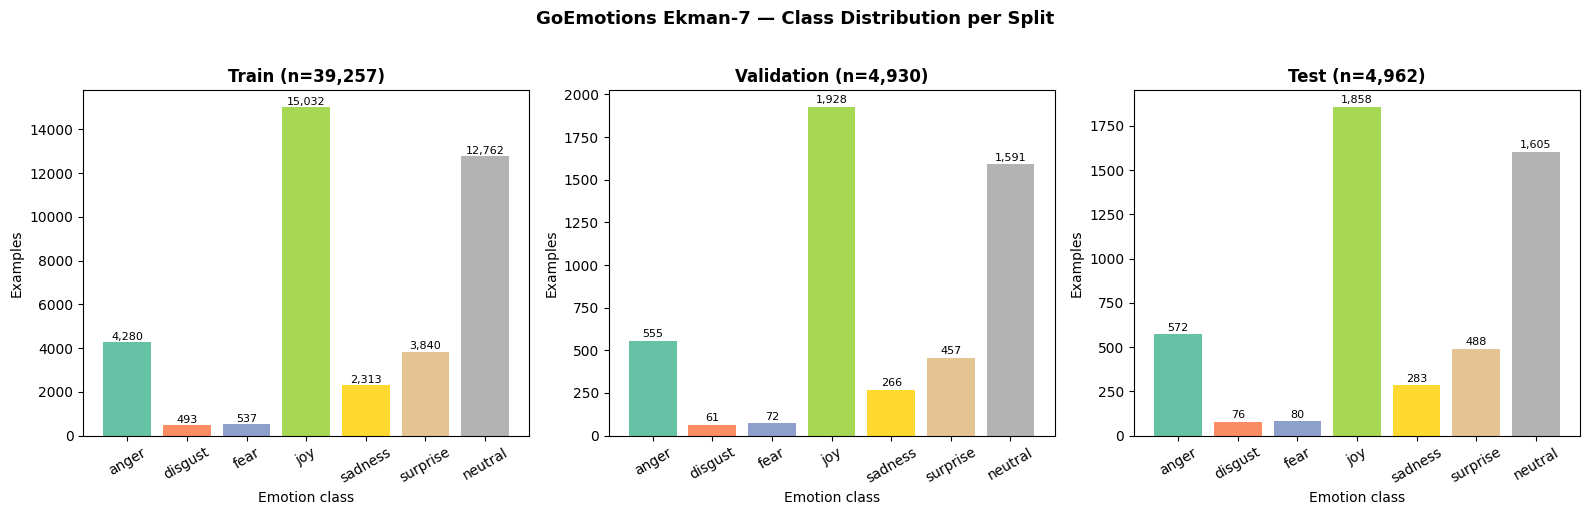

Figure saved: /content/Beyond-Words/outputs/english_emotion_condC/figures/class_distribution.png


In [12]:
# ── Visualise class distributions ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
colors = plt.cm.Set2(np.linspace(0, 1, NUM_LABELS))

for ax, split in zip(axes, ["train", "validation", "test"]):
    counts = [split_label_counts[split][lbl] for lbl in LABEL_ORDER]
    bars   = ax.bar(LABEL_ORDER, counts, color=colors)
    ax.set_title(f"{split.capitalize()} (n={sum(counts):,})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Emotion class")
    ax.set_ylabel("Examples")
    ax.tick_params(axis="x", rotation=30)
    for bar, cnt in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                f"{cnt:,}", ha="center", va="bottom", fontsize=8)

plt.suptitle("GoEmotions Ekman-7 — Class Distribution per Split",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = DIRS["out_figures"] / "class_distribution.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path}")


## Section 10 — Tokeniser loading

### What is a tokeniser?

A tokeniser converts raw text into a sequence of integer **token IDs** that the model can process. XLM-RoBERTa uses **SentencePiece** tokenisation with a vocabulary of 250,002 tokens covering 100 languages.

The tokeniser also produces:
- **`input_ids`** — the integer token IDs (including special tokens `<s>` and `</s>`)
- **`attention_mask`** — 1 for real tokens, 0 for padding; the model ignores padded positions

### Why preserve original text (not `text_norm`)?

XLM-RoBERTa's vocabulary includes both cased and uncased tokens. Lowercasing discards capitalisation signals that carry emotional weight ("WHY" vs "why"). We use the original `text` column, not the normalised `text_norm`.


In [13]:
print(f"Loading tokeniser: {CFG['model_name']}")
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"], revision=CFG["model_revision"])

print(f"Tokeniser class  : {type(tokenizer).__name__}")
print(f"Vocabulary size  : {tokenizer.vocab_size:,}")
print(f"Model max length : {tokenizer.model_max_length}")
print(f"Config max_seq_len: {CFG['max_seq_len']}")

# Sanity check on a sample with emotional content
sample_text   = "WHY THE FUCK IS THIS HAPPENING?! 😡"
sample_tokens = tokenizer(sample_text, return_tensors="pt")
token_strings = tokenizer.convert_ids_to_tokens(sample_tokens["input_ids"][0].tolist())
print(f"\nSample            : {sample_text!r}")
print(f"Token ids shape   : {sample_tokens['input_ids'].shape}")
print(f"Tokens            : {token_strings}")
print("\n✅  Tokeniser loaded successfully.")


Loading tokeniser: l3cube-pune/hing-roberta


tokenizer_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Tokeniser class  : XLMRobertaTokenizerFast
Vocabulary size  : 250,002
Model max length : 512
Config max_seq_len: 128

Sample            : 'WHY THE FUCK IS THIS HAPPENING?! 😡'
Token ids shape   : torch.Size([1, 17])
Tokens            : ['<s>', '▁W', 'HY', '▁THE', '▁FU', 'CK', '▁IS', '▁TH', 'IS', '▁H', 'APP', 'E', 'NING', '?!', '▁', '😡', '</s>']

✅  Tokeniser loaded successfully.


## Section 10b — Backbone and tokenizer verification (C vs XLM-R)

Before training, confirm what HingRoBERTa actually is:

- the architecture matches XLM-R base, so the classification head and optimiser settings are directly comparable;
- how often its tokenizer produces exactly the same token ids as XLM-R's on this corpus. If it is 100%, the two conditions differ only in backbone weights. If not, tokenisation is a second difference and must be reported;
- the exact Hub commit that was loaded.


In [14]:
from transformers import AutoConfig

_cfg_h = AutoConfig.from_pretrained(CFG["model_name"], revision=CFG["model_revision"])
_cfg_x = AutoConfig.from_pretrained("FacebookAI/xlm-roberta-base")

_keys = ["model_type", "num_hidden_layers", "hidden_size", "num_attention_heads",
         "intermediate_size", "vocab_size", "max_position_embeddings", "type_vocab_size"]
print(f"{'field':<26}{'HingRoBERTa':>16}{'XLM-R base':>16}")
for k in _keys:
    a, b = getattr(_cfg_h, k, None), getattr(_cfg_x, k, None)
    print(f"{k:<26}{str(a):>16}{str(b):>16}{'' if a == b else '   <-- differs'}")

assert _cfg_h.hidden_size == _cfg_x.hidden_size and _cfg_h.num_hidden_layers == _cfg_x.num_hidden_layers, \
    "Backbone dimensions differ from XLM-R base: classification heads are not directly comparable."

_tok_x = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-base")
_texts = df["text"].tolist()

def _encode_all(tok, texts, bs=2048):
    out = []
    for i in range(0, len(texts), bs):
        out.extend(tok(texts[i:i + bs], add_special_tokens=True,
                       truncation=False, padding=False)["input_ids"])
    return out

_ids_h = _encode_all(tokenizer, _texts)
_ids_x = _encode_all(_tok_x, _texts)
TOK_SAME_FRAC = float(np.mean([a == b for a, b in zip(_ids_h, _ids_x)]))
print(f"\nExamples with identical token ids (HingRoBERTa vs XLM-R tokenizer): {TOK_SAME_FRAC:.4%}")
print(f"Tokenizer vocab sizes: HingRoBERTa {len(tokenizer):,}  |  XLM-R {len(_tok_x):,}")
if TOK_SAME_FRAC < 1.0:
    print("NOTE: tokenisation differs from XLM-R. Report this as a second difference between A and C.")

RESOLVED_SHA = None
try:
    from huggingface_hub import HfApi
    RESOLVED_SHA = HfApi().model_info(CFG["model_name"], revision=CFG["model_revision"]).sha
    print("\nResolved Hub commit:", RESOLVED_SHA)
except Exception as _e:
    print("\nCould not resolve the Hub commit hash:", repr(_e)[:200])
del _tok_x, _ids_h, _ids_x


config.json:   0%|          | 0.00/750 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

field                          HingRoBERTa      XLM-R base
model_type                     xlm-roberta     xlm-roberta
num_hidden_layers                       12              12
hidden_size                            768             768
num_attention_heads                     12              12
intermediate_size                     3072            3072
vocab_size                          250002          250002
max_position_embeddings                514             514
type_vocab_size                          1               1


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Examples with identical token ids (HingRoBERTa vs XLM-R tokenizer): 100.0000%
Tokenizer vocab sizes: HingRoBERTa 250,002  |  XLM-R 250,002

Resolved Hub commit: f714c4bdce6b008a2fbb84193eee99e651c59e15


## Section 10b — Model forward-pass sanity check

### Why do this before training?

Loading a model and running it on two synthetic sentences takes a few seconds and
costs no GPU budget worth mentioning. It catches four classes of problem before we
commit to a 35-45 minute training run:

1. **Network download failure** — the checkpoint or config cannot be fetched from
   Hugging Face Hub.
2. **Shape mismatch** — if `NUM_LABELS`, `id2label`, or `label2id` are inconsistent,
   the classification head will have the wrong output dimension and the assertion
   `sample_logits.shape == (2, NUM_LABELS)` will fail.
3. **Non-finite logits** — `NaN` or `Inf` in the first forward pass indicates a
   configuration or precision issue, not a training problem.
4. **Device mismatch** — if inputs are on CPU but the model is on GPU (or vice versa),
   PyTorch raises an error here rather than deep inside the training loop.

The sanity model is deleted immediately after the check so GPU memory is fully
available for training.

In [15]:
# ── Model forward-pass sanity check ──────────────────────────────────────
# Temporarily load the model to verify architecture before training.
# This is NOT the training model — it is deleted as soon as the check passes.
print("=" * 60)
print("MODEL FORWARD-PASS SANITY CHECK")
print("=" * 60)

print(f"  Loading: {CFG['model_name']}")
_sanity_model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"],
    revision   = CFG["model_revision"],
    num_labels = NUM_LABELS,
    id2label   = ID2LABEL,
    label2id   = LABEL2ID,
).to(DEVICE)

# Two sentences chosen to exercise both positive and negative emotion tokens.
_sanity_texts = [
    "I am extremely happy and grateful today!",
    "I feel deeply disappointed and sad.",
]
_sanity_enc = tokenizer(
    _sanity_texts,
    padding        = True,
    truncation     = True,
    max_length     = CFG["max_seq_len"],
    return_tensors = "pt",
)
_sanity_enc = {k: v.to(DEVICE) for k, v in _sanity_enc.items()}

_sanity_model.eval()
with torch.no_grad():
    _sanity_logits = _sanity_model(**_sanity_enc).logits

# ── Assertions ────────────────────────────────────────────────────────────
assert _sanity_logits.shape == (len(_sanity_texts), NUM_LABELS), (
    f"Shape mismatch: expected ({len(_sanity_texts)}, {NUM_LABELS}), "
    f"got {tuple(_sanity_logits.shape)}. "
    f"Check NUM_LABELS, id2label, and label2id in the config."
)
assert torch.isfinite(_sanity_logits).all(), (
    "Forward pass produced NaN or Inf logits. "
    "Check dtype, device, and model configuration before training."
)

print(f"  Input shape  : {_sanity_enc['input_ids'].shape}  "
      f"(batch=2, tokens=padded length)")
print(f"  Output shape : {_sanity_logits.shape}  "
      f"(batch=2, classes={NUM_LABELS})")
print(f"  All logits finite: True")
print(f"  Label order  : {LABEL_ORDER}")
print()

# Show the raw logit vector for each sample to confirm the head is live
# (values will be near-random since the head is newly initialised,
# but they must be finite and of the correct dimension).
for i, text in enumerate(_sanity_texts):
    logit_str = "  ".join(f"{v:+.3f}" for v in _sanity_logits[i].tolist())
    print(f"  Sample {i+1}: {text[:45]!r}")
    print(f"    Logits: [{logit_str}]")
print()

# ── Clean up: free GPU memory before training ─────────────────────────────
del _sanity_model, _sanity_enc, _sanity_logits
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("[OK]  Model forward-pass sanity check passed.")
print("      GPU memory freed. Ready for training.")
print("=" * 60)

MODEL FORWARD-PASS SANITY CHECK
  Loading: l3cube-pune/hing-roberta


pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

  Input shape  : torch.Size([2, 10])  (batch=2, tokens=padded length)
  Output shape : torch.Size([2, 7])  (batch=2, classes=7)
  All logits finite: True
  Label order  : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'neutral']

  Sample 1: 'I am extremely happy and grateful today!'
    Logits: [-0.106  -0.152  -0.073  -0.217  -0.002  -0.411  +0.062]
  Sample 2: 'I feel deeply disappointed and sad.'
    Logits: [-0.035  -0.160  +0.001  -0.179  +0.107  -0.323  +0.023]

[OK]  Model forward-pass sanity check passed.
      GPU memory freed. Ready for training.


## Section 11 — Token-length analysis

### Why analyse token lengths?

The `max_seq_len` parameter **truncates** any text longer than 128 tokens. If many examples are longer than 128 tokens, truncation silently discards the end of those texts, potentially removing emotional content that appears at the end of a comment.

We compute:
- **Mean / median / 95th percentile** token length — to understand the distribution
- **Percentage truncated** — examples where `len(tokens) > max_seq_len`

### Decision rule

If > 10% of examples are truncated, consider increasing `max_seq_len` to 256. However, this roughly **doubles VRAM usage and computation cost**, and may exceed T4 capacity at batch size 16. The percentage truncated is the key number to report.

> This analysis takes ~1–2 minutes for 49k examples. Token lengths are computed without padding or truncation to measure actual lengths.


In [16]:
print("Computing token lengths on the full dataset (~1-2 minutes)...")

def get_token_lengths(texts: List[str], batch_size: int = 512) -> List[int]:
    """Tokenise texts in batches (no padding/truncation) and return raw lengths."""
    lengths = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        enc   = tokenizer(batch, add_special_tokens=True, truncation=False, padding=False)
        lengths.extend(len(ids) for ids in enc["input_ids"])
    return lengths

all_lengths    = get_token_lengths(df["text"].tolist())
df["token_len"] = all_lengths

for split in ["train", "validation", "test"]:
    lens          = df[df["split"] == split]["token_len"].values
    truncated_pct = (lens > CFG["max_seq_len"]).mean() * 100
    print(f"\n{split.upper()} (n={len(lens):,}):")
    print(f"  Mean              : {lens.mean():.1f} tokens")
    print(f"  Median            : {np.median(lens):.1f} tokens")
    print(f"  95th percentile   : {np.percentile(lens, 95):.1f} tokens")
    print(f"  Max               : {lens.max()} tokens")
    print(f"  % truncated (>{CFG['max_seq_len']}) : {truncated_pct:.2f}%")


Computing token lengths on the full dataset (~1-2 minutes)...

TRAIN (n=39,257):
  Mean              : 20.1 tokens
  Median            : 19.0 tokens
  95th percentile   : 36.0 tokens
  Max               : 339 tokens
  % truncated (>128) : 0.01%

VALIDATION (n=4,930):
  Mean              : 20.0 tokens
  Median            : 19.0 tokens
  95th percentile   : 36.0 tokens
  Max               : 48 tokens
  % truncated (>128) : 0.00%

TEST (n=4,962):
  Mean              : 20.0 tokens
  Median            : 19.0 tokens
  95th percentile   : 36.0 tokens
  Max               : 56 tokens
  % truncated (>128) : 0.00%


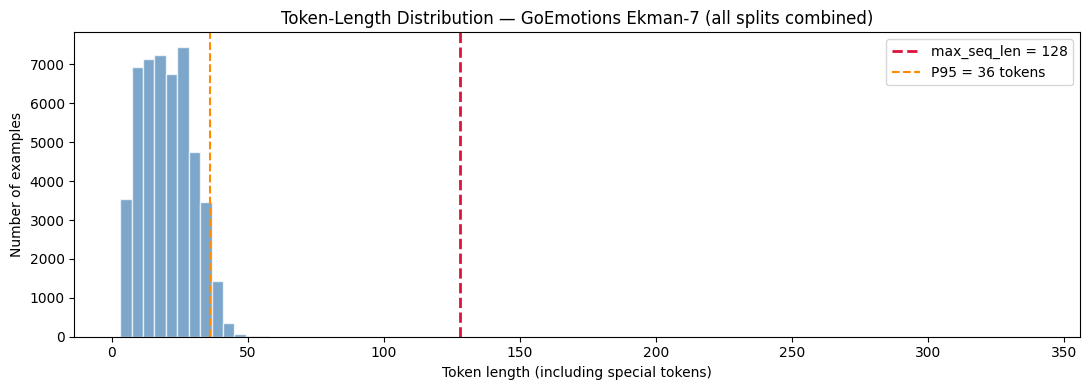

Figure saved: /content/Beyond-Words/outputs/english_emotion_condC/figures/token_length_distribution.png


In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(df["token_len"], bins=80, color="steelblue", alpha=0.7, edgecolor="white")
ax.axvline(CFG["max_seq_len"], color="crimson", linestyle="--", linewidth=2.0,
           label=f"max_seq_len = {CFG['max_seq_len']}")
p95 = np.percentile(df["token_len"], 95)
ax.axvline(p95, color="darkorange", linestyle="--", linewidth=1.5,
           label=f"P95 = {p95:.0f} tokens")
ax.set_xlabel("Token length (including special tokens)")
ax.set_ylabel("Number of examples")
ax.set_title("Token-Length Distribution — GoEmotions Ekman-7 (all splits combined)")
ax.legend()
plt.tight_layout()
fig_path = DIRS["out_figures"] / "token_length_distribution.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path}")


## Section 12 — Class-weight calculation

### Why ordinary cross-entropy fails on imbalanced data

Standard cross-entropy treats every example equally. Because Joy accounts for ~39% of training examples, the model is *rewarded* proportionally more for correctly classifying Joy. It may learn to favour Joy and Neutral at the expense of rare classes (Fear: ~1.8%, Disgust: ~1.6%).

### Class-weighted cross-entropy

We multiply the loss of each example by a weight inversely proportional to its class frequency:

$$w_c = \frac{N}{K \cdot n_c}$$

where:
- $N$ = total training examples
- $K$ = number of classes (7)
- $n_c$ = number of training examples in class $c$

A rare class like Fear gets a **higher weight**, so the optimiser is penalised more heavily for misclassifying Fear examples.

### Important caveats

- Class weighting changes the training objective but does **not guarantee** better macro-F1
- We will compare weighted vs unweighted as an ablation (set `CFG["use_class_weights"] = False`)
- Weights are computed **only from the training split** — never from validation or test data


In [18]:
# ── Compute class weights from training split only ─────────────────────────
# (Never compute from validation or test — that would be data leakage)
train_df         = df[df["split"] == "train"].copy()
train_labels_arr = train_df["mapped_label"].map(LABEL2ID).values  # integer array

# sklearn's balanced scheme: N / (K * count_c)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_LABELS),
    y=train_labels_arr,
)

CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights_array, dtype=torch.float32).to(DEVICE)

print(f"Class weights computed from {len(train_df):,} training examples\n")
print(f"{'Emotion':<12}  {'Train n':>10}  {'Weight':>10}")
print("-" * 38)
for i, lbl in enumerate(LABEL_ORDER):
    n = int((train_df["mapped_label"] == lbl).sum())
    print(f"{lbl:<12}  {n:>10,}  {class_weights_array[i]:>10.4f}")

print(f"\nNote: unweighted baseline uses weight = 1.0 for all classes.")
print(f"      Set CFG['use_class_weights'] = False to run the ablation.")
print(f"\n✅  Class weights tensor on device: {CLASS_WEIGHTS_TENSOR.device}")


Class weights computed from 39,257 training examples

Emotion          Train n      Weight
--------------------------------------
anger              4,280      1.3103
disgust              493     11.3755
fear                 537     10.4435
joy               15,032      0.3731
sadness            2,313      2.4246
surprise           3,840      1.4605
neutral           12,762      0.4394

Note: unweighted baseline uses weight = 1.0 for all classes.
      Set CFG['use_class_weights'] = False to run the ablation.

✅  Class weights tensor on device: cuda:0


## Section 13 — Dataset and DataLoader preparation

### PyTorch Dataset vs DataLoader

- A **`Dataset`** knows how to retrieve **one example** (tokenise text → tensors)
- A **`DataLoader`** batches multiple examples, shuffles training data each epoch, and uses parallel CPU workers for fast data loading

### Dynamic padding with DataCollatorWithPadding

Instead of padding every example to `max_seq_len` (128) regardless of actual length, `DataCollatorWithPadding` pads each **batch** to the longest sequence in that batch. This saves computation when most examples in a batch are short (the common case in GoEmotions).

### Why shuffle only training data?

Validation and test evaluation must be **deterministic** — identical results every time. Shuffling would change batch composition and could cause minor metric differences.


In [19]:
# ── EmotionDataset ────────────────────────────────────────────────────────
class EmotionDataset(Dataset):
    """PyTorch Dataset for seven-class emotion classification.

    Stores raw texts and example_ids alongside tensors for error analysis.
    Tokenisation uses truncation but NOT padding — dynamic padding is handled
    per-batch by EmotionDataCollator.
    """

    def __init__(
        self,
        texts       : List[str],
        labels      : List[int],
        example_ids : List[str],
        tokenizer   : AutoTokenizer,
        max_len     : int,
    ):
        self.texts       = texts
        self.labels      = labels
        self.example_ids = example_ids
        self.tokenizer   = tokenizer
        self.max_len     = max_len

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, idx: int) -> Dict:
        enc = self.tokenizer(
            self.texts[idx],
            truncation  = True,
            max_length  = self.max_len,
            padding     = False,     # padding handled by DataCollator
            return_tensors = "pt",
        )
        return {
            "input_ids"      : enc["input_ids"].squeeze(0),
            "attention_mask" : enc["attention_mask"].squeeze(0),
            "labels"         : torch.tensor(self.labels[idx], dtype=torch.long),
            "example_id"     : self.example_ids[idx],  # str — not a tensor
        }


# ── EmotionDataCollator ───────────────────────────────────────────────────
class EmotionDataCollator:
    """Collator that pads tensors per batch and passes string fields through."""

    def __init__(self, tokenizer: AutoTokenizer):
        self._pad = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

    def __call__(self, features: List[Dict]) -> Dict:
        # Pop string fields before passing to DataCollatorWithPadding
        example_ids = [f.pop("example_id") for f in features]
        batch       = self._pad(features)
        batch["example_id"] = example_ids
        return batch


# ── build_datasets ────────────────────────────────────────────────────────
def build_datasets(df: pd.DataFrame, tokenizer: AutoTokenizer, cfg: Dict) -> Dict:
    """Build EmotionDataset objects for all three splits."""
    datasets = {}
    for split in ["train", "validation", "test"]:
        sdf    = df[df["split"] == split].reset_index(drop=True)
        texts  = sdf["text"].tolist()
        labels = sdf["mapped_label"].map(LABEL2ID).tolist()
        ids    = sdf["example_id"].tolist()
        datasets[split] = EmotionDataset(texts, labels, ids, tokenizer, cfg["max_seq_len"])
    return datasets


# ── make_dataloaders ──────────────────────────────────────────────────────
def make_dataloaders(datasets: Dict, cfg: Dict, collator: EmotionDataCollator) -> Dict:
    """Wrap datasets in DataLoaders."""
    return {
        "train": DataLoader(
            datasets["train"],
            batch_size  = cfg["train_batch_size"],
            shuffle     = True,
            collate_fn  = collator,
            num_workers = 2,
            pin_memory  = CUDA_AVAILABLE,
        ),
        "validation": DataLoader(
            datasets["validation"],
            batch_size  = cfg["eval_batch_size"],
            shuffle     = False,
            collate_fn  = collator,
            num_workers = 2,
            pin_memory  = CUDA_AVAILABLE,
        ),
        "test": DataLoader(
            datasets["test"],
            batch_size  = cfg["eval_batch_size"],
            shuffle     = False,
            collate_fn  = collator,
            num_workers = 2,
            pin_memory  = CUDA_AVAILABLE,
        ),
    }


# Build and report
print("Building datasets...")
DATASETS = build_datasets(df, tokenizer, CFG)
for split_name, ds in DATASETS.items():
    print(f"  {split_name:>12} : {len(ds):>7,} examples")
print("\n✅  Datasets ready.")


Building datasets...
         train :  39,257 examples
    validation :   4,930 examples
          test :   4,962 examples

✅  Datasets ready.


## Section 14 — Model architecture and training utilities

### Architecture overview

```
Input text
   ↓
Tokeniser  (SentencePiece, vocab 250,002)
   ↓
XLM-RoBERTa-base Transformer  (12 layers · 768 hidden dim · 12 attention heads · 125M params)
   ↓
[CLS] token hidden state  (768-dim vector — summarises the whole sequence)
   ↓
Dropout (0.1)
   ↓
Linear layer  (768 → 7)   ← randomly initialised classification head
   ↓
Raw logits  (7 values, unbounded)
   ↓   argmax → predicted class
   ↓   softmax → probabilities (sum to 1)
```

### What are logits?

Logits are the **raw, unnormalised scores** from the final linear layer. They can be any real number. A higher logit means higher confidence for that class.

**Softmax** converts logits to probabilities:

$$p_c = \frac{e^{z_c}}{\sum_{j=1}^{7} e^{z_j}}$$

**Why save raw logits (not just predicted labels)?**

Two models can predict the same class with very different confidence:
- Model A: Joy logit = 4.5, Joy probability = 0.96
- Model B: Joy logit = 0.8, Joy probability = 0.42

If only the label "Joy" is saved, the confidence difference is permanently lost. Saving logits enables calibration analysis, uncertainty quantification on Hinglish data, and ensemble methods.

### Training step

Each training step:
1. **Forward pass**: compute logits and loss
2. **`loss.backward()`**: compute gradients via backpropagation
3. **Gradient clipping**: cap gradient norm at 1.0 to prevent instability
4. **`optimiser.step()`**: update weights using AdamW
5. **`scheduler.step()`**: adjust learning rate according to warmup/decay schedule

### Why AdamW (not Adam)?

AdamW decouples weight decay from the gradient update, which is more principled and produces better-calibrated regularisation for Transformer fine-tuning.

### Learning-rate schedule

Linear warmup (0 → 2e-5 over 10% of steps) followed by linear decay (2e-5 → 0 over remaining 90%). Warmup prevents corrupting pre-trained representations with high initial learning rates when the classification head weights are still random.


In [20]:
# ── Metric computation ────────────────────────────────────────────────────
def compute_metrics(
    true_labels : List[int],
    pred_labels : List[int],
    prefix      : str = "",
) -> Dict[str, float]:
    """Compute accuracy, macro-F1, and weighted-F1.

    Parameters
    ----------
    true_labels : ground-truth integer class indices
    pred_labels : predicted integer class indices
    prefix      : key prefix, e.g. 'val_' or 'test_'

    Returns
    -------
    dict mapping metric name → float value
    """
    return {
        f"{prefix}accuracy"    : accuracy_score(true_labels, pred_labels),
        f"{prefix}macro_f1"    : f1_score(true_labels, pred_labels, average="macro",    zero_division=0),
        f"{prefix}weighted_f1" : f1_score(true_labels, pred_labels, average="weighted", zero_division=0),
    }


# ── Training epoch ────────────────────────────────────────────────────────
def train_one_epoch(
    model     : nn.Module,
    loader    : DataLoader,
    optimiser : torch.optim.Optimizer,
    scheduler,
    loss_fn   : nn.Module,
    cfg       : Dict,
    scaler    : Optional[torch.cuda.amp.GradScaler],
    epoch     : int,
) -> float:
    """One full training epoch. Returns mean training loss.

    Gradient accumulation note
    --------------------------
    Every mini-batch loss is divided by the *actual size of its accumulation
    group*, not by the global grad_accum_steps.  This matters for the final
    group of the epoch: if grad_accum_steps=4 but only 2 batches remain, those
    gradients are divided by 2 (the true group size), not 4.  Using the global
    value would under-scale the final update.

    group_start = (step // accum_steps) * accum_steps
    group_size  = min(accum_steps, n_batches - group_start)

    Gradients are flushed at every grad_accum_steps boundary *and* at the very
    last batch, ensuring nothing is discarded.  total_steps in the LR scheduler
    uses ceiling division (see run_training) to match this count exactly.
    """
    model.train()
    total_loss  = 0.0
    n_steps     = 0
    accum_steps = cfg["grad_accum_steps"]
    optimiser.zero_grad()

    n_batches = len(loader)
    for step, batch in enumerate(loader):
        input_ids = batch["input_ids"].to(DEVICE)
        attn_mask = batch["attention_mask"].to(DEVICE)
        labels    = batch["labels"].to(DEVICE)

        # Actual number of batches in this accumulation group.
        # For a complete group this equals accum_steps.
        # For the final incomplete group it equals the remainder.
        group_start = (step // accum_steps) * accum_steps
        group_size  = min(accum_steps, n_batches - group_start)

        # Flush when we hit a group boundary or reach the very last batch.
        is_accum_step = (step + 1) % accum_steps == 0
        is_last_batch = (step + 1) == n_batches
        should_flush  = is_accum_step or is_last_batch

        if cfg["use_fp16"] and scaler is not None:
            with torch.cuda.amp.autocast():
                logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                # Divide by group_size, not accum_steps, so the final
                # incomplete group receives correctly-scaled gradients.
                loss   = loss_fn(logits, labels) / group_size
            scaler.scale(loss).backward()
            if should_flush:
                scaler.unscale_(optimiser)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                scaler.step(optimiser)
                scaler.update()
                scheduler.step()
                optimiser.zero_grad()
        else:
            logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
            loss   = loss_fn(logits, labels) / group_size
            loss.backward()
            if should_flush:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                optimiser.step()
                scheduler.step()
                optimiser.zero_grad()

        # Scale the logged loss back to per-example scale for display.
        total_loss += loss.item() * group_size
        n_steps    += 1

        if step % 200 == 0:
            print(f"    Epoch {epoch} | Step {step:>5}/{n_batches} "
                  f"| Loss (scaled) {loss.item() * group_size:.4f} "
                  f"| group_size {group_size}")

    return total_loss / n_steps


# ── Evaluation epoch ──────────────────────────────────────────────────────
def evaluate(
    model   : nn.Module,
    loader  : DataLoader,
    loss_fn : nn.Module,
    cfg     : Dict,
) -> Tuple[float, List[int], List[int], np.ndarray, List[str]]:
    """Evaluate model on a DataLoader.

    Returns
    -------
    mean_loss   : float
    true_labels : List[int]
    pred_labels : List[int]
    all_logits  : np.ndarray of shape (N, 7)  — raw logits for all examples
    example_ids : List[str]
    """
    model.eval()
    total_loss  = 0.0
    n_steps     = 0
    true_labels = []
    pred_labels = []
    all_logits  = []
    example_ids = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attn_mask = batch["attention_mask"].to(DEVICE)
            labels    = batch["labels"].to(DEVICE)
            ex_ids    = batch["example_id"]

            if cfg["use_fp16"]:
                with torch.cuda.amp.autocast():
                    logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                    loss   = loss_fn(logits, labels)
            else:
                logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                loss   = loss_fn(logits, labels)

            total_loss  += loss.item()
            n_steps     += 1
            true_labels .extend(labels.cpu().numpy().tolist())
            pred_labels .extend(logits.argmax(dim=-1).cpu().numpy().tolist())
            all_logits  .append(logits.float().cpu().numpy())
            example_ids .extend(ex_ids)

    return total_loss / n_steps, true_labels, pred_labels, np.vstack(all_logits), example_ids


print("✅  Training and evaluation functions defined.")


✅  Training and evaluation functions defined.


## Section 15 — Main training function

### Checkpoint selection strategy

After each epoch we evaluate on the **validation set** and record **validation macro-F1**. If macro-F1 improves, we:
1. Save model weights + tokeniser + config to `models/english_emotion/seed_{seed}/`
2. Record the best epoch and macro-F1 value

At the end of training we **reload the best checkpoint** and evaluate on the test set.

### Why macro-F1 for checkpoint selection?

Macro-F1 computes F1 for each of the 7 classes and averages them equally:

$$F1_{\text{macro}} = \frac{1}{7} \sum_{c=1}^{7} F1_c$$

A model that achieves 90% F1 on Joy/Neutral but 10% on Fear would score ~70% macro-F1 — clearly signalling poor minority-class performance. Accuracy would hide this problem.

### Expected training time (T4 GPU, batch 16, FP16, max_seq_len 128)

| Epochs | Approximate time |
|---|---|
| 1 | ~12–15 minutes |
| 3 | ~35–45 minutes |


In [21]:
def run_training(
    seed          : int,
    cfg           : Dict,
    df            : pd.DataFrame,
    tokenizer     : AutoTokenizer,
    class_weights : Optional[torch.Tensor],
) -> Dict:
    """Complete training run for one random seed.

    Parameters
    ----------
    seed          : integer seed for this independent run
    cfg           : experiment configuration dictionary
    df            : frozen dataset DataFrame
    tokenizer     : pre-loaded tokeniser (shared across runs)
    class_weights : weight tensor on DEVICE, or None for unweighted

    Returns
    -------
    dict with keys: seed, best_epoch, best_val_macro_f1, test_metrics,
                    history, checkpoint_dir, test_pred_df, val_pred_df
    """
    set_seed(seed)
    print(f"\n{'='*60}")
    print(f"TRAINING RUN — Seed {seed}  |  Condition {cfg['condition_label']}")
    print(f"{'='*60}")

    # ── Directories ───────────────────────────────────────────────────────
    # Include experiment_name and condition_label in the checkpoint path so
    # different backbone / condition runs never overwrite each other.
    # e.g.  models/english_emotion/xlmr_english_ekman7_condA/seed_42/
    exp_subdir     = f"{cfg['experiment_name']}_cond{cfg['condition_label']}"
    seed_model_dir = DIRS["models_root"] / exp_subdir / f"seed_{seed}"
    seed_model_dir.mkdir(parents=True, exist_ok=True)

    # ── DataLoaders (recreated per seed to get fresh shuffle state) ───────
    local_datasets = build_datasets(df, tokenizer, cfg)
    local_collator = EmotionDataCollator(tokenizer)
    loaders        = make_dataloaders(local_datasets, cfg, local_collator)

    # ── Model ─────────────────────────────────────────────────────────────
    print(f"\nLoading model: {cfg['model_name']}")
    model = AutoModelForSequenceClassification.from_pretrained(
        cfg["model_name"],
        revision   = cfg["model_revision"],
        num_labels = cfg["num_labels"],
        id2label   = ID2LABEL,
        label2id   = LABEL2ID,
    ).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"Parameters: {n_params:.1f}M")

    # ── Loss function ──────────────────────────────────────────────────────
    if cfg["use_class_weights"] and class_weights is not None:
        loss_fn = nn.CrossEntropyLoss(weight=class_weights)
        print("Loss: class-weighted CrossEntropyLoss")
    else:
        loss_fn = nn.CrossEntropyLoss()
        print("Loss: unweighted CrossEntropyLoss (ablation mode)")

    # ── Optimiser — AdamW with weight decay on non-bias/non-LayerNorm params
    no_decay    = ["bias", "LayerNorm.weight", "layer_norm.weight"]
    param_groups = [
        {"params": [p for n, p in model.named_parameters()
                    if not any(nd in n for nd in no_decay)],
         "weight_decay": cfg["weight_decay"]},
        {"params": [p for n, p in model.named_parameters()
                    if any(nd in n for nd in no_decay)],
         "weight_decay": 0.0},
    ]
    optimiser = torch.optim.AdamW(param_groups, lr=cfg["learning_rate"])

    # ── LR scheduler — linear warmup then linear decay ────────────────────
    # Ceiling division: the final incomplete accumulation group is flushed at
    # epoch end (see train_one_epoch), so it always produces one optimizer step.
    # Floor division would undercount and cause the scheduler to run out of
    # steps before the last optimizer update, zeroing the LR too early.
    import math
    steps_per_epoch = math.ceil(len(loaders["train"]) / cfg["grad_accum_steps"])
    total_steps     = steps_per_epoch * cfg["num_epochs"]
    warmup_steps    = int(total_steps * cfg["warmup_ratio"])
    scheduler    = get_linear_schedule_with_warmup(
        optimiser,
        num_warmup_steps  = warmup_steps,
        num_training_steps = total_steps,
    )
    print(f"Total steps: {total_steps}  |  Warmup steps: {warmup_steps}")

    # ── Mixed-precision scaler ────────────────────────────────────────────
    scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None

    # ── Training loop ──────────────────────────────────────────────────────
    history           = []
    best_macro_f1     = -1.0
    best_epoch        = -1
    best_val_pred_df  = None

    for epoch in range(1, cfg["num_epochs"] + 1):
        t0         = time.time()
        train_loss = train_one_epoch(model, loaders["train"], optimiser,
                                     scheduler, loss_fn, cfg, scaler, epoch)
        val_loss, val_true, val_pred, val_logits, val_ids = evaluate(
            model, loaders["validation"], loss_fn, cfg)
        val_metrics = compute_metrics(val_true, val_pred, prefix="val_")
        elapsed     = time.time() - t0

        print(f"\n  Epoch {epoch}/{cfg['num_epochs']} summary:")
        print(f"    Train loss   : {train_loss:.4f}")
        print(f"    Val loss     : {val_loss:.4f}")
        print(f"    Val accuracy : {val_metrics['val_accuracy']:.4f}")
        print(f"    Val macro-F1 : {val_metrics['val_macro_f1']:.4f}  ← checkpoint metric")
        print(f"    Val wtd-F1   : {val_metrics['val_weighted_f1']:.4f}")
        print(f"    Epoch time   : {elapsed:.0f}s")

        history.append({
            "epoch"       : epoch,
            "train_loss"  : train_loss,
            "val_loss"    : val_loss,
            **val_metrics,
            "epoch_time_s": elapsed,
        })

        # ── Save best checkpoint ──────────────────────────────────────────
        if val_metrics["val_macro_f1"] > best_macro_f1:
            best_macro_f1 = val_metrics["val_macro_f1"]
            best_epoch    = epoch
            model.save_pretrained(seed_model_dir)
            tokenizer.save_pretrained(seed_model_dir)

            # Build validation predictions dataframe
            val_probs    = scipy_softmax(val_logits, axis=1)
            best_val_pred_df = pd.DataFrame({
                "example_id" : val_ids,
                "true_label" : [ID2LABEL[i] for i in val_true],
                "pred_label" : [ID2LABEL[i] for i in val_pred],
                "correct"    : [t == p for t, p in zip(val_true, val_pred)],
                **{f"logit_{ID2LABEL[i]}": val_logits[:, i] for i in range(NUM_LABELS)},
                **{f"prob_{ID2LABEL[i]}":  val_probs[:, i]  for i in range(NUM_LABELS)},
            })
            # Overwrite val logits file with best-epoch version
            val_logit_path = DIRS["out_logits"] / f"val_logits_{cfg['experiment_name']}_cond{cfg['condition_label']}_seed{seed}_best_epoch{epoch}.csv"
            best_val_pred_df.to_csv(val_logit_path, index=False)

            print(f"  ✅  New best checkpoint saved "
                  f"(val macro-F1 = {best_macro_f1:.4f}, epoch {epoch})")

    # ── Reload best checkpoint → evaluate on test set ─────────────────────
    print(f"\nReloading best checkpoint (epoch {best_epoch}, "
          f"val macro-F1 = {best_macro_f1:.4f})")
    best_model = AutoModelForSequenceClassification.from_pretrained(
        str(seed_model_dir)).to(DEVICE)

    test_loss, test_true, test_pred, test_logits, test_ids = evaluate(
        best_model, loaders["test"], loss_fn, cfg)
    test_metrics = compute_metrics(test_true, test_pred, prefix="test_")

    print(f"\n{'='*60}")
    print(f"TEST SET RESULTS — Seed {seed}")
    print(f"{'='*60}")
    print(f"  Test loss        : {test_loss:.4f}")
    print(f"  Test accuracy    : {test_metrics['test_accuracy']:.4f}")
    print(f"  Test macro-F1    : {test_metrics['test_macro_f1']:.4f}")
    print(f"  Test weighted-F1 : {test_metrics['test_weighted_f1']:.4f}")
    print(classification_report(
        test_true, test_pred,
        target_names = LABEL_ORDER,
        labels       = list(range(NUM_LABELS)),
        zero_division = 0,
    ))

    # ── Save test logits ───────────────────────────────────────────────────
    test_probs   = scipy_softmax(test_logits, axis=1)
    test_pred_df = pd.DataFrame({
        "example_id" : test_ids,
        "true_label" : [ID2LABEL[i] for i in test_true],
        "pred_label" : [ID2LABEL[i] for i in test_pred],
        "correct"    : [t == p for t, p in zip(test_true, test_pred)],
        **{f"logit_{ID2LABEL[i]}": test_logits[:, i] for i in range(NUM_LABELS)},
        **{f"prob_{ID2LABEL[i]}":  test_probs[:, i]  for i in range(NUM_LABELS)},
    })
    test_logit_path = DIRS["out_logits"] / f"test_logits_{cfg['experiment_name']}_cond{cfg['condition_label']}_seed{seed}.csv"
    test_pred_df.to_csv(test_logit_path, index=False)
    print(f"Test logits saved: {test_logit_path}")

    # ── Save training history ──────────────────────────────────────────────
    history_path = DIRS["out_logs"] / f"training_history_{cfg['experiment_name']}_cond{cfg['condition_label']}_seed{seed}.json"
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

    # ── Save run metadata ──────────────────────────────────────────────────
    run_meta = {
        "seed"             : seed,
        "best_epoch"       : best_epoch,
        "best_val_macro_f1": best_macro_f1,
        "test_metrics"     : test_metrics,
        "checkpoint_dir"   : str(seed_model_dir),
        "label_order"      : LABEL_ORDER,
        "cfg"              : {k: str(v) for k, v in cfg.items()},
    }
    with open(seed_model_dir / "run_metadata.json", "w") as f:
        json.dump(run_meta, f, indent=2)

    return {
        "seed"             : seed,
        "best_epoch"       : best_epoch,
        "best_val_macro_f1": best_macro_f1,
        "test_metrics"     : test_metrics,
        "history"          : history,
        "checkpoint_dir"   : str(seed_model_dir),
        "test_pred_df"     : test_pred_df,
        "val_pred_df"      : best_val_pred_df,
    }


print("✅  run_training() function defined. Ready to execute.")


✅  run_training() function defined. Ready to execute.


## Section 16 — Calibration analysis

### What is calibration?

A well-calibrated model should assign probability 0.80 to predictions it is correct on exactly 80% of the time. If a model predicts 0.95 confidence but is only correct 60% of the time, it is **overconfident**.

This matters for Beyond Words because overconfident predictions on Hinglish examples would mask genuine uncertainty — confidence is a signal for disagreement between surface sentiment and intended emotion.

### Expected Calibration Error (ECE)

We divide predictions into $B$ equal-width probability bins. For each bin $b$:

$$\text{ECE} = \sum_{b=1}^{B} \frac{|\mathcal{B}_b|}{N} \left| \text{acc}(\mathcal{B}_b) - \text{conf}(\mathcal{B}_b) \right|$$

A perfect calibration gives ECE = 0. Typical fine-tuned transformers have ECE ≈ 0.05–0.15. We use 15 equal-width bins.

### Brier Score (multiclass)

$$\text{BS} = \frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{K} (p_{ic} - y_{ic})^2$$

where $y_{ic} = 1$ if example $i$ belongs to class $c$, else 0. Lower is better.

> ⚠️ Calibration analysis uses **validation probabilities only** for any fitting. Raw uncalibrated predictions are always preserved.


In [22]:
def compute_ece(
    true_labels : List[int],
    probs       : np.ndarray,
    n_bins      : int = 15,
) -> float:
    """Expected Calibration Error.

    Uses max-probability (confidence) as the binning dimension.

    Parameters
    ----------
    true_labels : ground-truth integer class indices (N,)
    probs       : softmax probability matrix (N, K)
    n_bins      : number of equal-width confidence bins (default 15)

    Returns
    -------
    float : ECE score (lower = better; 0 = perfect calibration)
    """
    max_probs   = probs.max(axis=1)
    pred_labels = probs.argmax(axis=1)
    correct     = (pred_labels == np.array(true_labels)).astype(float)
    bin_edges   = np.linspace(0.0, 1.0, n_bins + 1)
    ece         = 0.0
    n_total     = len(true_labels)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (max_probs >= lo) & (max_probs < hi)
        if in_bin.sum() == 0:
            continue
        acc_b = correct[in_bin].mean()
        con_b = max_probs[in_bin].mean()
        ece  += (in_bin.sum() / n_total) * abs(acc_b - con_b)

    return float(ece)


def compute_brier_score(
    true_labels : List[int],
    probs       : np.ndarray,
    num_classes : int,
) -> float:
    """Multiclass Brier Score.

    Parameters
    ----------
    true_labels : ground-truth integer class indices (N,)
    probs       : softmax probability matrix (N, K)
    num_classes : number of classes K

    Returns
    -------
    float : mean Brier score (lower = better; 0 = perfect)
    """
    n       = len(true_labels)
    one_hot = np.zeros((n, num_classes), dtype=float)
    for i, lbl in enumerate(true_labels):
        one_hot[i, lbl] = 1.0
    return float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))


def calibration_plot(
    true_labels : List[int],
    probs       : np.ndarray,
    split_name  : str,
    seed        : int,
    n_bins      : int = 15,
    save_dir    : Optional[Path] = None,
) -> None:
    """Reliability diagram + confidence histogram."""
    max_probs   = probs.max(axis=1)
    pred_labels = probs.argmax(axis=1)
    correct     = (pred_labels == np.array(true_labels)).astype(float)
    bin_edges   = np.linspace(0, 1, n_bins + 1)
    bin_centers, acc_per_bin, conf_per_bin = [], [], []

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (max_probs >= lo) & (max_probs < hi)
        if in_bin.sum() == 0:
            continue
        bin_centers.append((lo + hi) / 2)
        acc_per_bin.append(correct[in_bin].mean())
        conf_per_bin.append(max_probs[in_bin].mean())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect calibration")
    ax1.bar(bin_centers, acc_per_bin, width=1 / n_bins * 0.9,
            alpha=0.6, color="steelblue", label="Accuracy per bin")
    ax1.set_xlabel("Mean confidence (max probability)")
    ax1.set_ylabel("Fraction correct")
    ax1.set_title(f"Reliability Diagram — {split_name} (seed {seed})")
    ax1.legend()

    ax2.hist(max_probs, bins=40, color="steelblue", alpha=0.7, edgecolor="white")
    ax2.set_xlabel("Max predicted probability")
    ax2.set_ylabel("Count")
    ax2.set_title("Confidence Distribution")

    plt.tight_layout()
    if save_dir:
        fig_path = save_dir / f"calibration_{split_name}_seed{seed}.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()


def run_calibration_analysis(result: Dict) -> Dict:
    """Compute ECE and Brier score for a completed training run."""
    seed      = result["seed"]
    prob_cols = [f"prob_{lbl}" for lbl in LABEL_ORDER]

    val_df    = result["val_pred_df"]
    val_true  = [LABEL2ID[lbl] for lbl in val_df["true_label"]]
    val_probs = val_df[prob_cols].values

    test_df    = result["test_pred_df"]
    test_true  = [LABEL2ID[lbl] for lbl in test_df["true_label"]]
    test_probs = test_df[prob_cols].values

    val_ece    = compute_ece(val_true,  val_probs,  n_bins=15)
    val_brier  = compute_brier_score(val_true,  val_probs,  NUM_LABELS)
    test_ece   = compute_ece(test_true, test_probs, n_bins=15)
    test_brier = compute_brier_score(test_true, test_probs, NUM_LABELS)

    print(f"\n── Calibration — Seed {seed} ──")
    print(f"  Val  ECE   : {val_ece:.4f}  (lower = better)")
    print(f"  Val  Brier : {val_brier:.4f}")
    print(f"  Test ECE   : {test_ece:.4f}")
    print(f"  Test Brier : {test_brier:.4f}")

    calibration_plot(val_true,  val_probs,  "validation", seed, save_dir=DIRS["out_figures"])
    calibration_plot(test_true, test_probs, "test",       seed, save_dir=DIRS["out_figures"])

    # Save calibration metrics
    cal_path = DIRS["out_metrics"] / f"calibration_seed{seed}.json"
    with open(cal_path, "w") as f:
        json.dump({"seed": seed, "val_ece": val_ece, "val_brier": val_brier,
                   "test_ece": test_ece, "test_brier": test_brier}, f, indent=2)

    return {"seed": seed, "val_ece": val_ece, "val_brier": val_brier,
            "test_ece": test_ece, "test_brier": test_brier}


print("✅  Calibration functions defined.")


✅  Calibration functions defined.


## Section 17 — Error analysis

Error analysis helps us understand **where and why the model fails**, not just how often.

### High-confidence errors

These are the most informative failure cases — the model was very certain (e.g., 95% confidence) but wrong. They reveal **systematic model biases**, not random mistakes.

### Expected confusion patterns

- Anger ↔ Disgust: both are negative, aversive emotions — often linguistically similar
- Joy ↔ Surprise: excited, positive text can be ambiguous
- Sadness ↔ Neutral: low-affect sad text may be hard to distinguish from neutral

Unexpected confusions (e.g., Sadness predicted as Joy) indicate a more serious problem and should be investigated by reading the actual examples.

### Why we display examples

Automated confusion matrices alone can miss important patterns. Manual review of high-confidence errors is a core part of responsible NLP research.


In [23]:
def plot_confusion_matrix(
    true_labels : List[int],
    pred_labels : List[int],
    label_names : List[str],
    seed        : int,
    split       : str = "test",
    save_dir    : Optional[Path] = None,
) -> None:
    """Plot raw-count and row-normalised confusion matrices side-by-side."""
    cm      = confusion_matrix(true_labels, pred_labels, labels=list(range(len(label_names))))
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    kw = dict(xticklabels=label_names, yticklabels=label_names)

    sns.heatmap(cm,      annot=True, fmt="d",    cmap="Blues", ax=ax1, **kw)
    ax1.set_title(f"Confusion Matrix — Raw Counts\n{split} split (seed {seed})")
    ax1.set_xlabel("Predicted"); ax1.set_ylabel("True")

    sns.heatmap(cm_norm, annot=True, fmt=".2f",  cmap="Blues", ax=ax2, **kw)
    ax2.set_title(f"Confusion Matrix — Row-Normalised (Recall)\n{split} split (seed {seed})")
    ax2.set_xlabel("Predicted"); ax2.set_ylabel("True")

    plt.tight_layout()
    if save_dir:
        fig_path = save_dir / f"confusion_matrix_{split}_seed{seed}.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()


def run_error_analysis(
    result     : Dict,
    df         : pd.DataFrame,
    n_examples : int = 10,
    split      : str = "test",
) -> None:
    """Display confusion matrix, per-class report, and example errors."""
    seed      = result["seed"]
    pred_df   = result[f"{split}_pred_df"].copy()
    prob_cols = [f"prob_{lbl}" for lbl in LABEL_ORDER]

    true_int = [LABEL2ID[lbl] for lbl in pred_df["true_label"]]
    pred_int = [LABEL2ID[lbl] for lbl in pred_df["pred_label"]]

    plot_confusion_matrix(true_int, pred_int, LABEL_ORDER, seed=seed,
                          split=split, save_dir=DIRS["out_figures"])

    print(f"\n── Per-class report ({split}, seed {seed}) ──")
    print(classification_report(true_int, pred_int, target_names=LABEL_ORDER,
                                 labels=list(range(NUM_LABELS)), zero_division=0))

    pred_df["max_prob"]     = pred_df[prob_cols].max(axis=1)
    id_to_text              = dict(zip(df["example_id"], df["text"]))
    pred_df["original_text"] = pred_df["example_id"].map(id_to_text)

    errors  = pred_df[~pred_df["correct"]].copy()
    correct = pred_df[pred_df["correct"]].copy()

    print(f"\n── Error summary ({split}, seed {seed}) ──")
    print(f"  Total     : {len(pred_df):,}")
    print(f"  Correct   : {len(correct):,}  ({len(correct)/len(pred_df)*100:.1f}%)")
    print(f"  Incorrect : {len(errors):,}  ({len(errors)/len(pred_df)*100:.1f}%)")

    print(f"\n── Top {n_examples} highest-confidence ERRORS ──")
    for _, row in errors.nlargest(n_examples, "max_prob").iterrows():
        txt = str(row["original_text"])[:80]
        print(f"  True: {row['true_label']:<10} Pred: {row['pred_label']:<10} "
              f"Conf: {row['max_prob']:.3f}  │  {txt!r}")

    print(f"\n── Top {n_examples} lowest-confidence CORRECT predictions ──")
    for _, row in correct.nsmallest(n_examples, "max_prob").iterrows():
        txt = str(row["original_text"])[:80]
        print(f"  True: {row['true_label']:<10} Pred: {row['pred_label']:<10} "
              f"Conf: {row['max_prob']:.3f}  │  {txt!r}")

    err_path = DIRS["out_predictions"] / f"errors_{split}_seed{seed}.csv"
    display_cols = ["example_id","true_label","pred_label","correct","max_prob"] + prob_cols
    errors[display_cols].to_csv(err_path, index=False)
    print(f"\nError CSV saved: {err_path}")


print("✅  Error analysis functions defined.")


✅  Error analysis functions defined.


## Section 18 — Results aggregation and training curves

After running all seeds, we aggregate results into a summary table with mean and standard deviation.

### Why mean ± std?

A single run may be unusually good or bad due to weight initialisation, data-loading order, and other stochastic effects. Three seeds give an **initial estimate** of run-to-run variability. Standard deviation quantifies this.

$$\text{Mean} = \frac{1}{3} \sum_{i=1}^{3} S_i$$

Three seeds are a practical starting point. For publication-quality results, more seeds or a held-out validation approach (e.g., 5-fold CV) would be appropriate.

> Do not average raw logits from different seeds to produce ensemble predictions unless a separate ensemble experiment is explicitly designed and documented.


In [24]:
def aggregate_results(
    all_results : List[Dict],
    all_calib   : List[Dict],
) -> pd.DataFrame:
    """Build a summary DataFrame from multi-seed results."""
    rows = []
    for res, cal in zip(all_results, all_calib):
        rows.append({
            "seed"              : res["seed"],
            "best_epoch"        : res["best_epoch"],
            "best_val_macro_f1" : res["best_val_macro_f1"],
            "test_accuracy"     : res["test_metrics"]["test_accuracy"],
            "test_macro_f1"     : res["test_metrics"]["test_macro_f1"],
            "test_weighted_f1"  : res["test_metrics"]["test_weighted_f1"],
            "val_ece"           : cal["val_ece"],
            "val_brier"         : cal["val_brier"],
            "test_ece"          : cal["test_ece"],
            "test_brier"        : cal["test_brier"],
        })

    df_sum = pd.DataFrame(rows)
    num_cols = [c for c in df_sum.columns if c not in ("seed", "best_epoch")]
    mean_row = {"seed": "mean", "best_epoch": ""}
    std_row  = {"seed": "std",  "best_epoch": ""}
    for col in num_cols:
        mean_row[col] = df_sum[col].mean()
        std_row[col]  = df_sum[col].std(ddof=1)
    df_sum = pd.concat([df_sum, pd.DataFrame([mean_row, std_row])], ignore_index=True)
    return df_sum


def plot_training_curves(all_results: List[Dict]) -> None:
    """Plot loss and macro-F1 curves for all seeds."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    colors = ["steelblue", "darkorange", "forestgreen"]

    for color, res in zip(colors, all_results):
        h       = res["history"]
        epochs  = [r["epoch"]          for r in h]
        tl      = [r["train_loss"]     for r in h]
        vl      = [r["val_loss"]       for r in h]
        vm      = [r["val_macro_f1"]   for r in h]
        seed    = res["seed"]
        ax1.plot(epochs, tl, "--", color=color, alpha=0.6, label=f"train s{seed}")
        ax1.plot(epochs, vl, "-",  color=color,            label=f"val   s{seed}")
        ax2.plot(epochs, vm, "-o", color=color,            label=f"seed {seed}")

    ax1.set_title("Loss Curves (all seeds)")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend(fontsize=8)
    ax2.set_title("Validation Macro-F1 (all seeds)")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Macro-F1"); ax2.legend()

    plt.suptitle(
        f"Training History — {CFG['experiment_name']}  (Condition {CFG['condition_label']})",
        fontsize=13, fontweight="bold")
    plt.tight_layout()
    fig_path = DIRS["out_figures"] / "training_curves_all_seeds.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Figure saved: {fig_path}")


print("✅  Aggregation and plotting functions defined.")


✅  Aggregation and plotting functions defined.


## Section 18b — 20-step smoke test

Runs 20 real optimiser steps on the real training loader with the real loss, optimiser, mixed precision and gradient clipping. It takes about a minute and catches out-of-memory errors, non-finite losses and tokenizer/model mismatches before a 40-minute run. It does not touch any saved file.


In [26]:
print("=" * 60)
print("SMOKE TEST (20 steps)")
print("=" * 60)
set_seed(0)
_ds     = build_datasets(df, tokenizer, CFG)
_coll   = EmotionDataCollator(tokenizer)
_loader = make_dataloaders(_ds, CFG, _coll)["train"]

_model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"], revision=CFG["model_revision"],
    num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID,
).to(DEVICE)
_loss_fn = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_TENSOR if CFG["use_class_weights"] else None)
_opt     = torch.optim.AdamW(_model.parameters(), lr=CFG["learning_rate"], weight_decay=CFG["weight_decay"])
_scaler  = torch.cuda.amp.GradScaler() if CFG["use_fp16"] else None
if CUDA_AVAILABLE:
    torch.cuda.reset_peak_memory_stats()

_model.train()
_losses = []
for _step, _batch in enumerate(_loader):
    if _step >= 20:
        break
    _ids  = _batch["input_ids"].to(DEVICE)
    _mask = _batch["attention_mask"].to(DEVICE)
    _lab  = _batch["labels"].to(DEVICE)
    _opt.zero_grad()
    if CFG["use_fp16"]:
        with torch.cuda.amp.autocast():
            _loss = _loss_fn(_model(input_ids=_ids, attention_mask=_mask).logits, _lab)
        _scaler.scale(_loss).backward()
        _scaler.unscale_(_opt)
        _gn = torch.nn.utils.clip_grad_norm_(_model.parameters(), CFG["grad_clip"])
        _scaler.step(_opt)
        _scaler.update()
    else:
        _loss = _loss_fn(_model(input_ids=_ids, attention_mask=_mask).logits, _lab)
        _loss.backward()
        _gn = torch.nn.utils.clip_grad_norm_(_model.parameters(), CFG["grad_clip"])
        _opt.step()
    _losses.append(_loss.item())
    assert np.isfinite(_losses[-1]), f"Non-finite loss at step {_step}"

print(f"  Steps run        : {len(_losses)}")
print(f"  First / last loss: {_losses[0]:.4f} / {_losses[-1]:.4f}")
print(f"  Last grad norm   : {float(_gn):.3f}")
if CUDA_AVAILABLE:
    print(f"  Peak GPU memory  : {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
del _model, _opt, _scaler, _loader, _ds
if CUDA_AVAILABLE:
    torch.cuda.empty_cache()
print("[OK] Smoke test passed.")


SMOKE TEST (20 steps)
🌱  Random seed set to 0


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_2501/3410057402.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  _scaler  = torch.cuda.amp.GradScaler() if CFG["use_fp16"] else None
/tmp/ipykernel_2501/3410057402.py:29: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  Steps run        : 20
  First / last loss: 1.8390 / 1.7998
  Last grad norm   : 5.671
  Peak GPU memory  : 5.59 GB
[OK] Smoke test passed.


## Section 19 — Single-seed run (pipeline verification)

> ⚠️ **Run this section first.** Complete one full training run with seed 42 before attempting the three-seed loop. This catches data-loading errors, shape mismatches, and OOM errors early, without wasting GPU time on a broken pipeline.

### If you encounter a CUDA out-of-memory error:

1. Reduce `CFG["train_batch_size"]` from 16 → 8
2. Increase `CFG["grad_accum_steps"]` from 1 → 2 (keeps effective batch = 16)
3. Reduce `CFG["max_seq_len"]` from 128 → 96
4. **Restart the runtime** (Runtime → Restart runtime) and re-run from the top

Document any deviation from the planned configuration. Do not silently change settings mid-run.

### Expected output of a successful single-seed run

- Checkpoint saved to `models/english_emotion/seed_42/`
- Validation logits CSV in `outputs/english_emotion/logits/`
- Test logits CSV in `outputs/english_emotion/logits/`
- Training history JSON in `outputs/english_emotion/logs/`
- Calibration plots in `outputs/english_emotion/figures/`
- Confusion matrix in `outputs/english_emotion/figures/`


In [27]:
# ── Set this flag to True for first run; False after pipeline is verified ──
SINGLE_SEED_DEBUG = False   # <-- change to False before running Section 20

if SINGLE_SEED_DEBUG:
    print("Pipeline verification mode: running seed 42 only.")
    print("After this succeeds, set SINGLE_SEED_DEBUG = False and run Section 20.\n")

    result_debug  = run_training(
        seed          = 42,
        cfg           = CFG,
        df            = df,
        tokenizer     = tokenizer,
        class_weights = CLASS_WEIGHTS_TENSOR if CFG["use_class_weights"] else None,
    )
    calib_debug   = run_calibration_analysis(result_debug)
    run_error_analysis(result_debug, df, n_examples=10, split="test")

    print("\n" + "="*60)
    print("SINGLE-SEED VERIFICATION COMPLETE")
    print("="*60)
    print(f"  Test macro-F1  : {result_debug['test_metrics']['test_macro_f1']:.4f}")
    print(f"  Test weighted-F1: {result_debug['test_metrics']['test_weighted_f1']:.4f}")
    print(f"  Test ECE       : {calib_debug['test_ece']:.4f}")
    print(f"  Best epoch     : {result_debug['best_epoch']}")
    print("\nIf all outputs look correct, set SINGLE_SEED_DEBUG = False")
    print("in this cell and run Section 20 (multi-seed).")
else:
    print("SINGLE_SEED_DEBUG is False — skipping. Proceed to Section 20.")


SINGLE_SEED_DEBUG is False — skipping. Proceed to Section 20.


## Section 20 — Multi-seed experiment (resumable)

Trains each seed in `SEEDS_TO_RUN`. A seed is skipped if a finished run with the **same configuration** already exists on disk, so you can:

- run one seed per Colab session (`SEEDS_TO_RUN = [42]`, then `[123]`, then `[2026]`), or
- re-run the cell after a disconnect without repeating finished seeds.

Aggregation is done from disk in Section 20b, so it does not depend on one session having run all three seeds.

| Seeds | Approximate time (T4, 3 epochs each) |
|---|---|
| 1 | about 40 minutes |
| 3 | about 2 hours |


🌱  Random seed set to 42

TRAINING RUN — Seed 42  |  Condition C

Loading model: l3cube-pune/hing-roberta


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 278.0M
Loss: class-weighted CrossEntropyLoss
Total steps: 7362  |  Warmup steps: 736


/tmp/ipykernel_2501/1904138533.py:90: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None
/tmp/ipykernel_2501/3696150764.py:78: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


    Epoch 1 | Step     0/2454 | Loss (scaled) 1.8764 | group_size 1
    Epoch 1 | Step   200/2454 | Loss (scaled) 1.7012 | group_size 1
    Epoch 1 | Step   400/2454 | Loss (scaled) 1.4534 | group_size 1
    Epoch 1 | Step   600/2454 | Loss (scaled) 0.9049 | group_size 1
    Epoch 1 | Step   800/2454 | Loss (scaled) 0.7706 | group_size 1
    Epoch 1 | Step  1000/2454 | Loss (scaled) 1.3337 | group_size 1
    Epoch 1 | Step  1200/2454 | Loss (scaled) 1.4077 | group_size 1
    Epoch 1 | Step  1400/2454 | Loss (scaled) 1.2883 | group_size 1
    Epoch 1 | Step  1600/2454 | Loss (scaled) 0.5677 | group_size 1
    Epoch 1 | Step  1800/2454 | Loss (scaled) 1.0049 | group_size 1
    Epoch 1 | Step  2000/2454 | Loss (scaled) 0.5565 | group_size 1
    Epoch 1 | Step  2200/2454 | Loss (scaled) 0.4837 | group_size 1
    Epoch 1 | Step  2400/2454 | Loss (scaled) 0.7136 | group_size 1


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (7 outputs left out)

/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



  Epoch 3/3 summary:
    Train loss   : 0.6793
    Val loss     : 1.0707
    Val accuracy : 0.6919
    Val macro-F1 : 0.6212  ← checkpoint metric
    Val wtd-F1   : 0.6938
    Epoch time   : 419s

Reloading best checkpoint (epoch 2, val macro-F1 = 0.6219)


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



TEST SET RESULTS — Seed 42
  Test loss        : 0.9579
  Test accuracy    : 0.6945
  Test macro-F1    : 0.6448
  Test weighted-F1 : 0.6972
              precision    recall  f1-score   support

       anger       0.54      0.61      0.57       572
     disgust       0.47      0.62      0.54        76
        fear       0.64      0.82      0.72        80
         joy       0.86      0.82      0.84      1858
     sadness       0.53      0.72      0.61       283
    surprise       0.51      0.75      0.61       488
     neutral       0.72      0.55      0.63      1605

    accuracy                           0.69      4962
   macro avg       0.61      0.70      0.64      4962
weighted avg       0.71      0.69      0.70      4962

Test logits saved: /content/Beyond-Words/outputs/english_emotion_condC/logits/test_logits_hingroberta_english_ekman7_condC_seed42.csv

── Calibration — Seed 42 ──
  Val  ECE   : 0.0799  (lower = better)
  Val  Brier : 0.4375
  Test ECE   : 0.0765
  Test Brier : 0

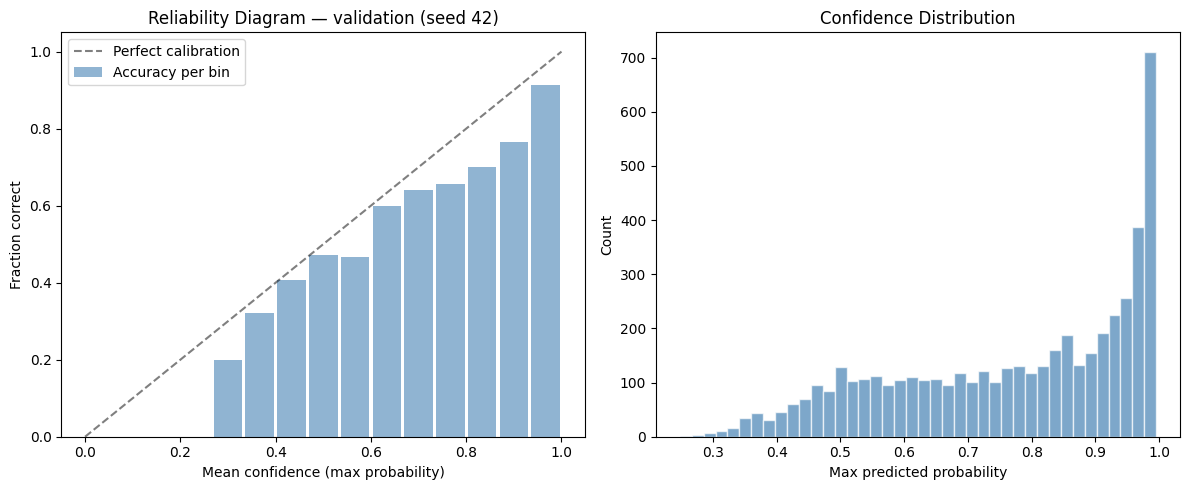

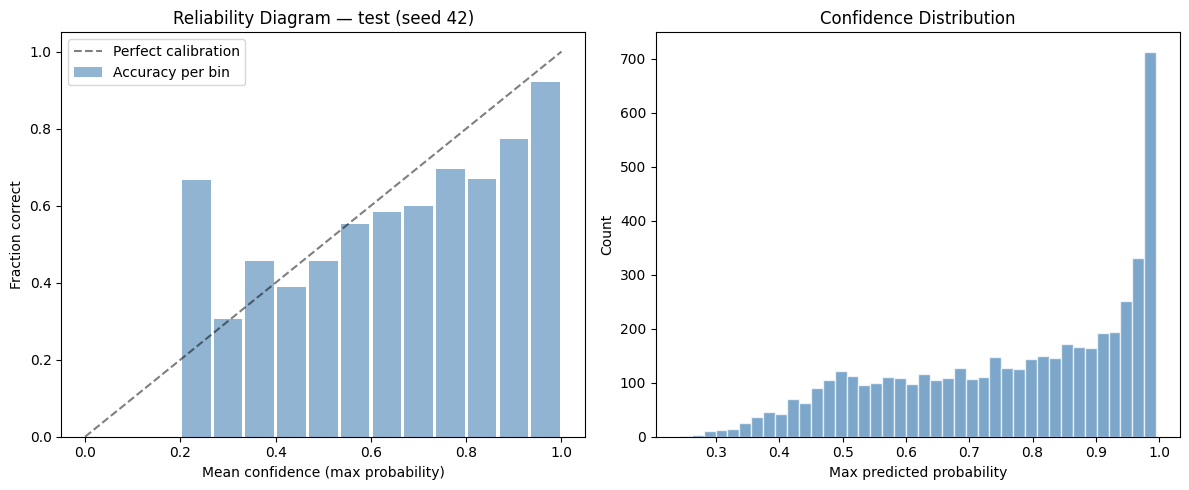

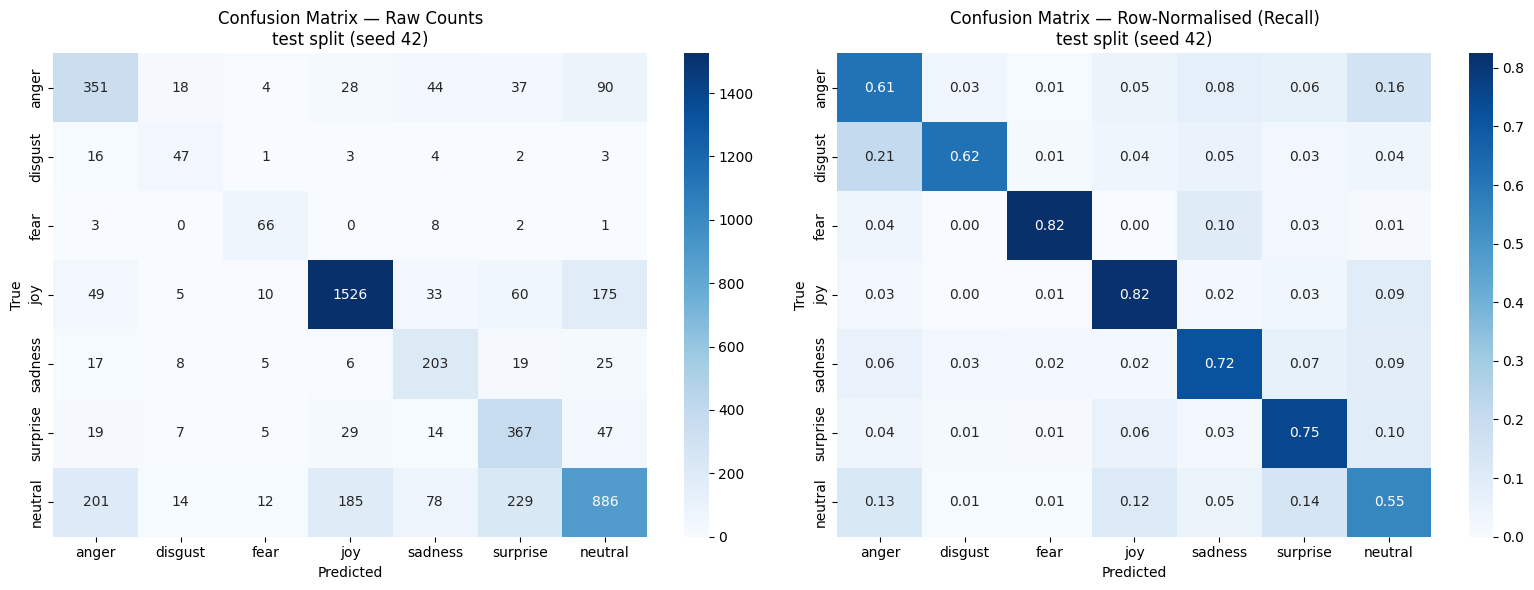


── Per-class report (test, seed 42) ──
              precision    recall  f1-score   support

       anger       0.54      0.61      0.57       572
     disgust       0.47      0.62      0.54        76
        fear       0.64      0.82      0.72        80
         joy       0.86      0.82      0.84      1858
     sadness       0.53      0.72      0.61       283
    surprise       0.51      0.75      0.61       488
     neutral       0.72      0.55      0.63      1605

    accuracy                           0.69      4962
   macro avg       0.61      0.70      0.64      4962
weighted avg       0.71      0.69      0.70      4962


── Error summary (test, seed 42) ──
  Total     : 4,962
  Correct   : 3,446  (69.4%)
  Incorrect : 1,516  (30.6%)

── Top 5 highest-confidence ERRORS ──
  True: surprise   Pred: fear       Conf: 0.994  │  'Oh. I have anxiety for her and this conversation.'
  True: neutral    Pred: fear       Conf: 0.993  │  "What happened to one of your star players?? i saw th

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 278.0M
Loss: class-weighted CrossEntropyLoss
Total steps: 7362  |  Warmup steps: 736


/tmp/ipykernel_2501/1904138533.py:90: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None
/tmp/ipykernel_2501/3696150764.py:78: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


    Epoch 1 | Step     0/2454 | Loss (scaled) 2.0475 | group_size 1
    Epoch 1 | Step   200/2454 | Loss (scaled) 2.1717 | group_size 1
    Epoch 1 | Step   400/2454 | Loss (scaled) 1.2000 | group_size 1
    Epoch 1 | Step   600/2454 | Loss (scaled) 0.8798 | group_size 1
    Epoch 1 | Step   800/2454 | Loss (scaled) 1.0569 | group_size 1
    Epoch 1 | Step  1000/2454 | Loss (scaled) 0.3790 | group_size 1
    Epoch 1 | Step  1200/2454 | Loss (scaled) 0.3995 | group_size 1
    Epoch 1 | Step  1400/2454 | Loss (scaled) 1.9859 | group_size 1
    Epoch 1 | Step  1600/2454 | Loss (scaled) 1.1706 | group_size 1
    Epoch 1 | Step  1800/2454 | Loss (scaled) 0.8536 | group_size 1
    Epoch 1 | Step  2000/2454 | Loss (scaled) 1.6423 | group_size 1
    Epoch 1 | Step  2200/2454 | Loss (scaled) 0.1778 | group_size 1
    Epoch 1 | Step  2400/2454 | Loss (scaled) 0.2503 | group_size 1


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (7 outputs left out)

/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



  Epoch 3/3 summary:
    Train loss   : 0.6886
    Val loss     : 1.0756
    Val accuracy : 0.6890
    Val macro-F1 : 0.6129  ← checkpoint metric
    Val wtd-F1   : 0.6913
    Epoch time   : 414s

Reloading best checkpoint (epoch 2, val macro-F1 = 0.6288)


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



TEST SET RESULTS — Seed 123
  Test loss        : 0.9779
  Test accuracy    : 0.6945
  Test macro-F1    : 0.6413
  Test weighted-F1 : 0.6956
              precision    recall  f1-score   support

       anger       0.52      0.65      0.58       572
     disgust       0.56      0.58      0.57        76
        fear       0.54      0.80      0.65        80
         joy       0.84      0.83      0.83      1858
     sadness       0.62      0.61      0.61       283
    surprise       0.53      0.76      0.63       488
     neutral       0.71      0.55      0.62      1605

    accuracy                           0.69      4962
   macro avg       0.62      0.68      0.64      4962
weighted avg       0.71      0.69      0.70      4962

Test logits saved: /content/Beyond-Words/outputs/english_emotion_condC/logits/test_logits_hingroberta_english_ekman7_condC_seed123.csv

── Calibration — Seed 123 ──
  Val  ECE   : 0.0823  (lower = better)
  Val  Brier : 0.4297
  Test ECE   : 0.0837
  Test Brier 

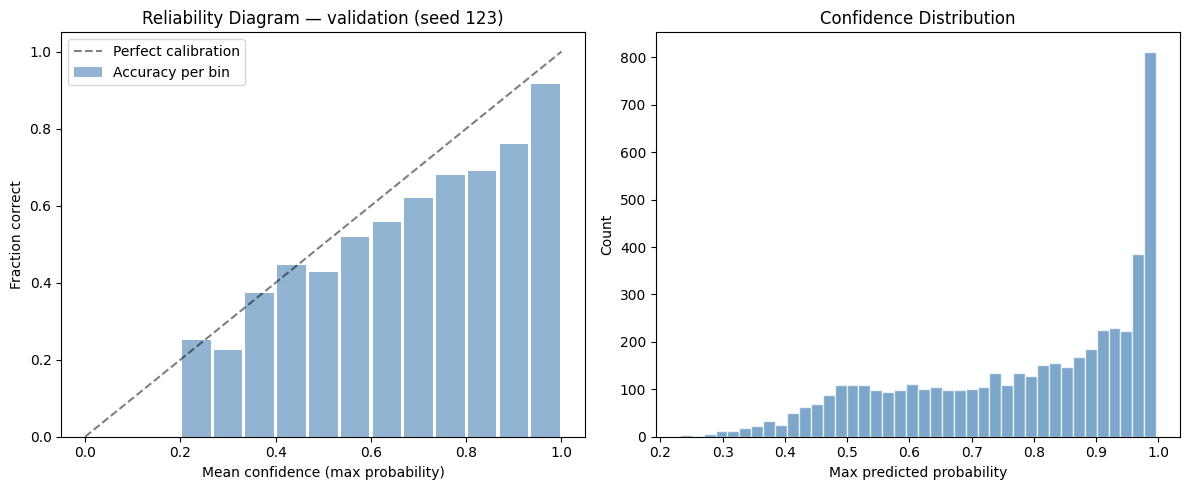

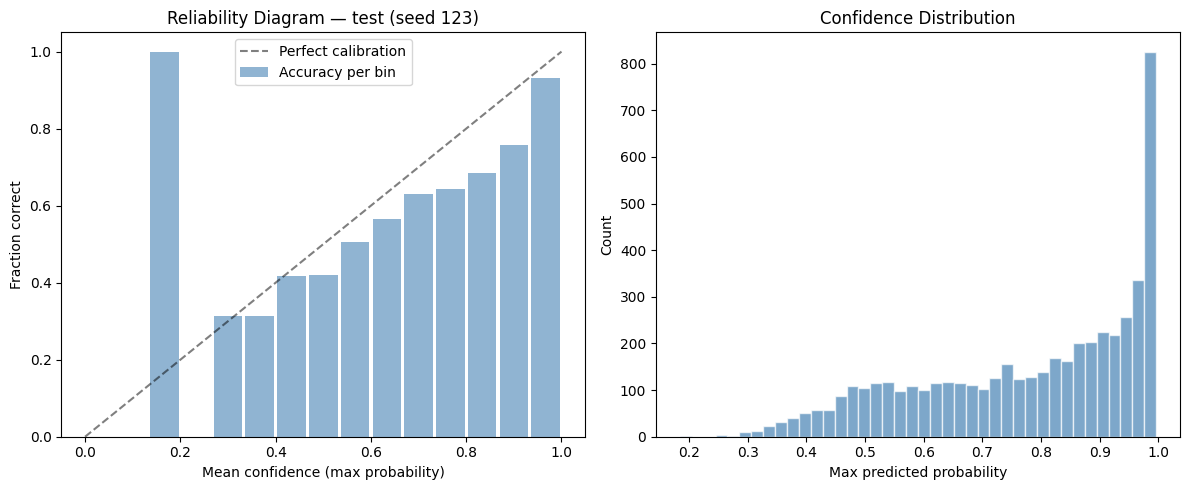

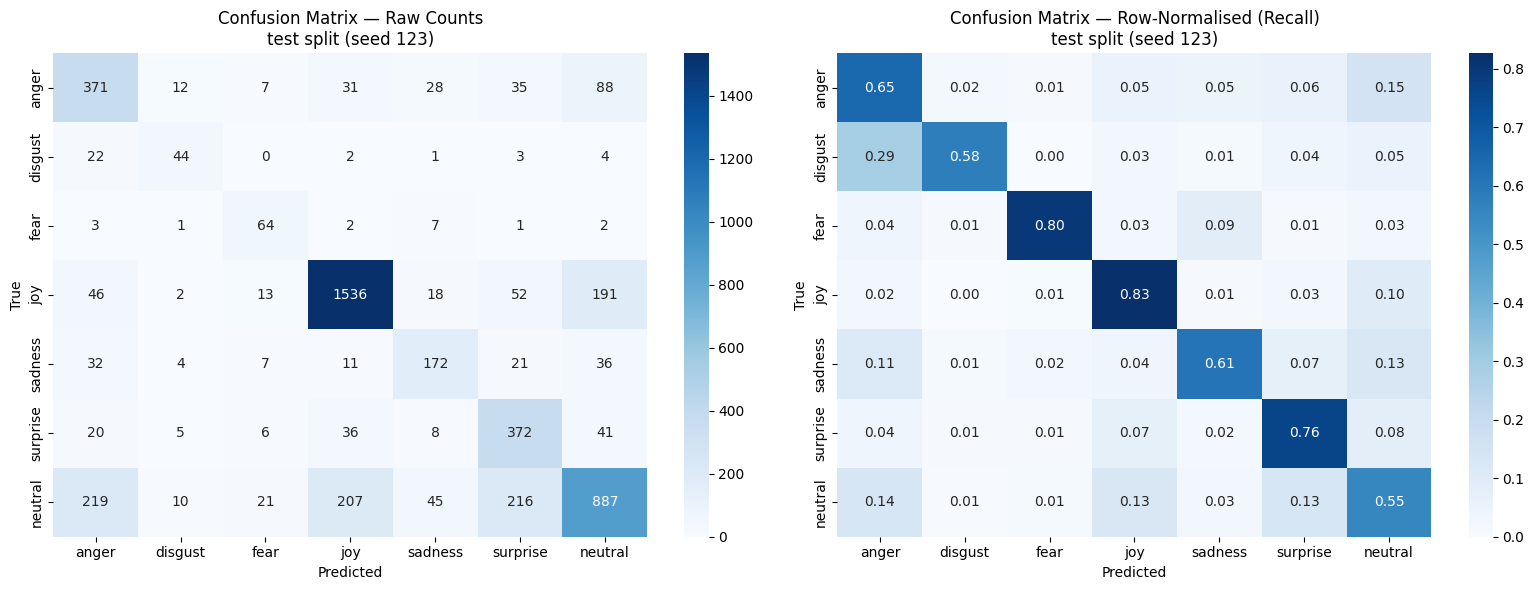


── Per-class report (test, seed 123) ──
              precision    recall  f1-score   support

       anger       0.52      0.65      0.58       572
     disgust       0.56      0.58      0.57        76
        fear       0.54      0.80      0.65        80
         joy       0.84      0.83      0.83      1858
     sadness       0.62      0.61      0.61       283
    surprise       0.53      0.76      0.63       488
     neutral       0.71      0.55      0.62      1605

    accuracy                           0.69      4962
   macro avg       0.62      0.68      0.64      4962
weighted avg       0.71      0.69      0.70      4962


── Error summary (test, seed 123) ──
  Total     : 4,962
  Correct   : 3,446  (69.4%)
  Incorrect : 1,516  (30.6%)

── Top 5 highest-confidence ERRORS ──
  True: neutral    Pred: fear       Conf: 0.996  │  "What happened to one of your star players?? i saw the headline 'freak injury' or"
  True: surprise   Pred: fear       Conf: 0.996  │  'Oh. I have anxiety 

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 278.0M
Loss: class-weighted CrossEntropyLoss
Total steps: 7362  |  Warmup steps: 736


/tmp/ipykernel_2501/1904138533.py:90: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None
/tmp/ipykernel_2501/3696150764.py:78: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


    Epoch 1 | Step     0/2454 | Loss (scaled) 1.9056 | group_size 1
    Epoch 1 | Step   200/2454 | Loss (scaled) 2.5257 | group_size 1
    Epoch 1 | Step   400/2454 | Loss (scaled) 1.2493 | group_size 1
    Epoch 1 | Step   600/2454 | Loss (scaled) 1.0726 | group_size 1
    Epoch 1 | Step   800/2454 | Loss (scaled) 0.9381 | group_size 1
    Epoch 1 | Step  1000/2454 | Loss (scaled) 0.7735 | group_size 1
    Epoch 1 | Step  1200/2454 | Loss (scaled) 0.6561 | group_size 1
    Epoch 1 | Step  1400/2454 | Loss (scaled) 0.6903 | group_size 1
    Epoch 1 | Step  1600/2454 | Loss (scaled) 1.1743 | group_size 1
    Epoch 1 | Step  1800/2454 | Loss (scaled) 1.0148 | group_size 1
    Epoch 1 | Step  2000/2454 | Loss (scaled) 0.6597 | group_size 1
    Epoch 1 | Step  2200/2454 | Loss (scaled) 0.5150 | group_size 1
    Epoch 1 | Step  2400/2454 | Loss (scaled) 0.5190 | group_size 1


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (7 outputs left out)

/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



  Epoch 3/3 summary:
    Train loss   : 0.6775
    Val loss     : 1.0616
    Val accuracy : 0.6941
    Val macro-F1 : 0.6225  ← checkpoint metric
    Val wtd-F1   : 0.6960
    Epoch time   : 413s
  ✅  New best checkpoint saved (val macro-F1 = 0.6225, epoch 3)

Reloading best checkpoint (epoch 3, val macro-F1 = 0.6225)


/tmp/ipykernel_2501/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



TEST SET RESULTS — Seed 2026
  Test loss        : 1.0160
  Test accuracy    : 0.6902
  Test macro-F1    : 0.6358
  Test weighted-F1 : 0.6922
              precision    recall  f1-score   support

       anger       0.48      0.68      0.56       572
     disgust       0.47      0.63      0.54        76
        fear       0.57      0.74      0.64        80
         joy       0.85      0.83      0.84      1858
     sadness       0.57      0.71      0.63       283
    surprise       0.55      0.72      0.62       488
     neutral       0.74      0.53      0.61      1605

    accuracy                           0.69      4962
   macro avg       0.60      0.69      0.64      4962
weighted avg       0.71      0.69      0.69      4962

Test logits saved: /content/Beyond-Words/outputs/english_emotion_condC/logits/test_logits_hingroberta_english_ekman7_condC_seed2026.csv

── Calibration — Seed 2026 ──
  Val  ECE   : 0.1154  (lower = better)
  Val  Brier : 0.4507
  Test ECE   : 0.1120
  Test Bri

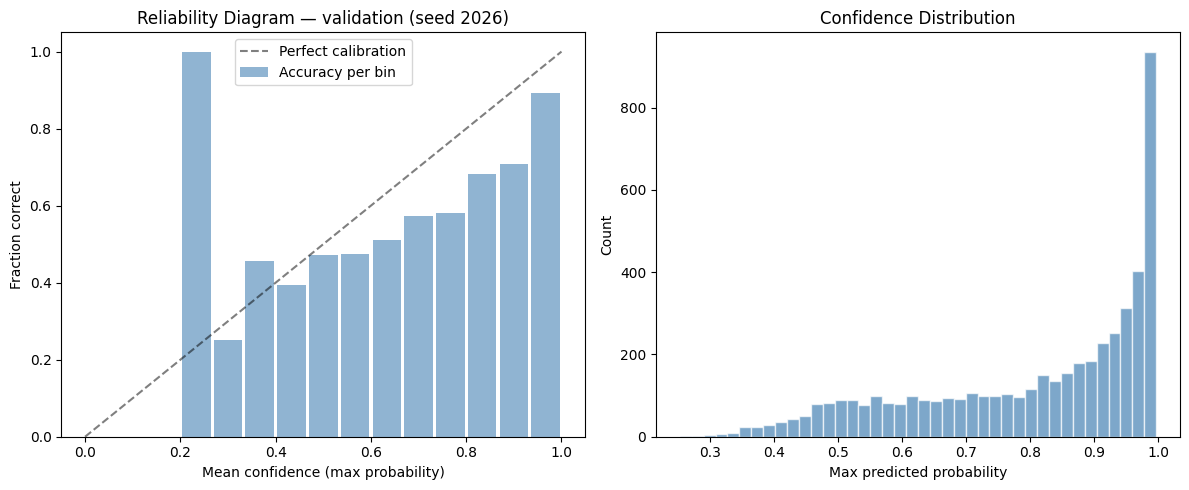

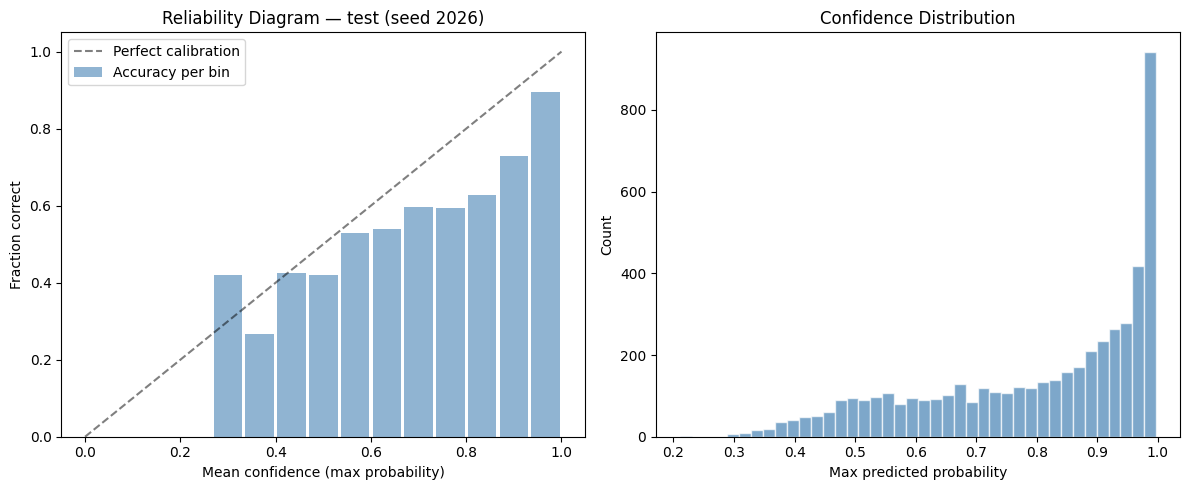

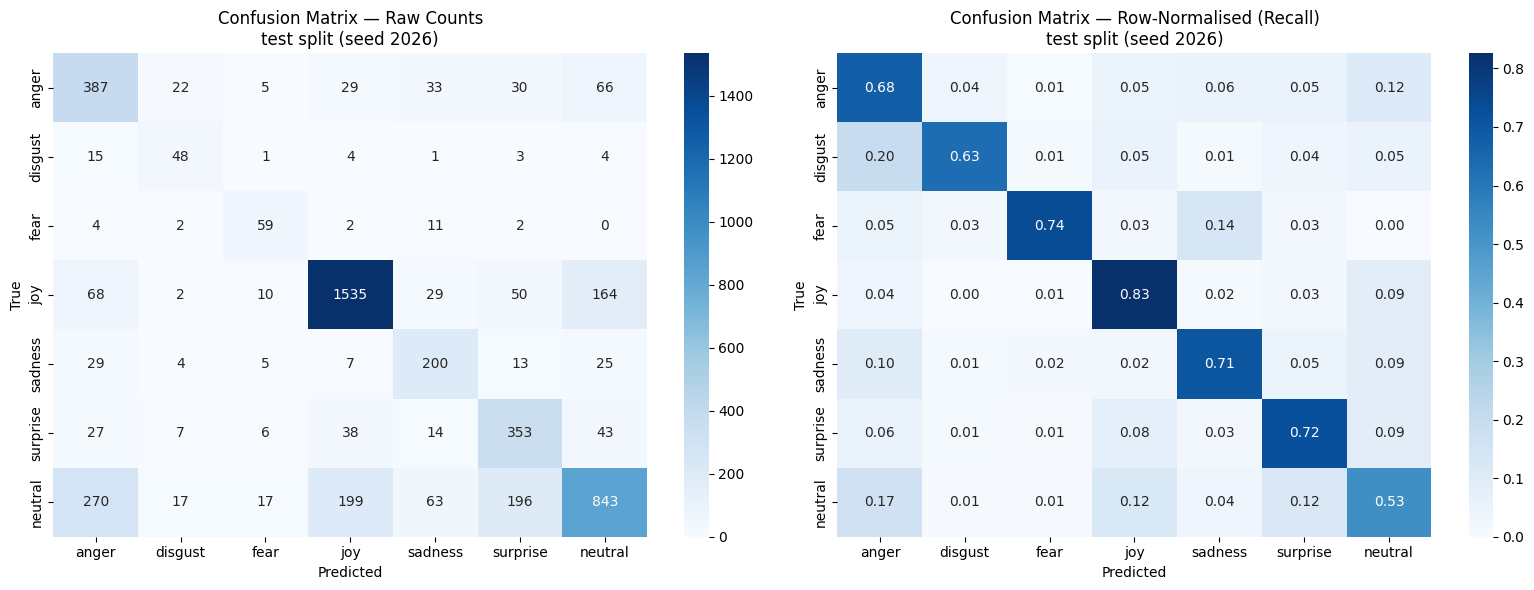


── Per-class report (test, seed 2026) ──
              precision    recall  f1-score   support

       anger       0.48      0.68      0.56       572
     disgust       0.47      0.63      0.54        76
        fear       0.57      0.74      0.64        80
         joy       0.85      0.83      0.84      1858
     sadness       0.57      0.71      0.63       283
    surprise       0.55      0.72      0.62       488
     neutral       0.74      0.53      0.61      1605

    accuracy                           0.69      4962
   macro avg       0.60      0.69      0.64      4962
weighted avg       0.71      0.69      0.69      4962


── Error summary (test, seed 2026) ──
  Total     : 4,962
  Correct   : 3,425  (69.0%)
  Incorrect : 1,537  (31.0%)

── Top 5 highest-confidence ERRORS ──
  True: neutral    Pred: fear       Conf: 0.997  │  "What happened to one of your star players?? i saw the headline 'freak injury' or"
  True: surprise   Pred: fear       Conf: 0.997  │  'Oh. I have anxiet

In [28]:
SEEDS_TO_RUN   = list(CFG["seeds"])     # e.g. [42] to run one seed in this session
SKIP_COMPLETED = True
RUN_MULTI_SEED = not SINGLE_SEED_DEBUG

_exp_cond = f"{CFG['experiment_name']}_cond{CFG['condition_label']}"

def seed_is_complete(seed: int) -> bool:
    """A seed counts as finished only if its metadata and test logits exist AND it was run with this CFG."""
    meta_p = DIRS["models_root"] / _exp_cond / f"seed_{seed}" / "run_metadata.json"
    logit_p = DIRS["out_logits"] / f"test_logits_{_exp_cond}_seed{seed}.csv"
    if not (meta_p.exists() and logit_p.exists()):
        return False
    saved_cfg = json.loads(meta_p.read_text()).get("cfg", {})
    return saved_cfg == {k: str(v) for k, v in CFG.items()}

all_results = []
all_calib   = []

if RUN_MULTI_SEED:
    for seed in SEEDS_TO_RUN:
        if SKIP_COMPLETED and seed_is_complete(seed):
            print(f"Seed {seed}: already complete with identical CFG, skipping.")
            continue
        result = run_training(
            seed          = seed,
            cfg           = CFG,
            df            = df,
            tokenizer     = tokenizer,
            class_weights = CLASS_WEIGHTS_TENSOR if CFG["use_class_weights"] else None,
        )
        calib = run_calibration_analysis(result)
        run_error_analysis(result, df, n_examples=5, split="test")
        all_results.append(result)
        all_calib.append(calib)
    print("\nTraining loop finished. Run Section 20b to aggregate all seeds from disk.")
else:
    print("Multi-seed run skipped (SINGLE_SEED_DEBUG = True in Section 19).")


## Section 20b — Aggregate all seeds from disk

Rebuilds every seed's result from the saved files, so it works after several sessions. Produces the multi-seed summary, training curves and per-class tables (precision, recall, F1, support; mean and standard deviation across seeds). It stops with a clear message if a seed is missing or was trained with a different configuration.


MULTI-SEED RESULTS SUMMARY — Condition C
seed best_epoch  best_val_macro_f1  test_accuracy  test_macro_f1  test_weighted_f1  val_ece  val_brier  test_ece  test_brier
  42          2             0.6219         0.6945         0.6448            0.6972   0.0799     0.4375    0.0765      0.4367
 123          2             0.6288         0.6945         0.6413            0.6956   0.0823     0.4297    0.0837      0.4310
2026          3             0.6225         0.6902         0.6358            0.6922   0.1154     0.4507    0.1120      0.4516
mean                        0.6244         0.6931         0.6406            0.6950   0.0925     0.4393    0.0907      0.4398
 std                        0.0038         0.0024         0.0046            0.0026   0.0199     0.0106    0.0188      0.0107


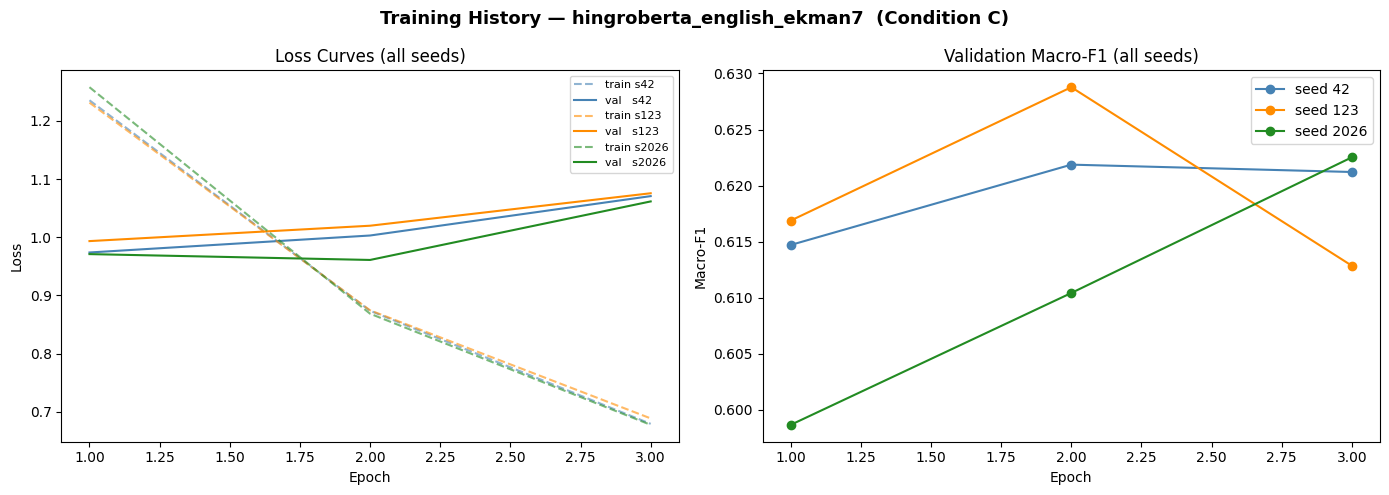

Figure saved: /content/Beyond-Words/outputs/english_emotion_condC/figures/training_curves_all_seeds.png

Per-class test metrics, mean and SD over seeds (Condition C):
   label  support  precision_mean  precision_sd  recall_mean  recall_sd  f1_mean  f1_sd
   anger      572           0.513         0.026        0.646      0.032    0.571  0.007
 disgust       76           0.503         0.053        0.610      0.027    0.549  0.019
    fear       80           0.585         0.050        0.787      0.045    0.671  0.044
     joy     1858           0.849         0.009        0.825      0.003    0.837  0.003
 sadness      283           0.572         0.044        0.677      0.060    0.617  0.012
surprise      488           0.530         0.017        0.746      0.020    0.619  0.009
 neutral     1605           0.723         0.013        0.543      0.016    0.620  0.006


In [29]:
from sklearn.metrics import precision_recall_fscore_support

def load_result_from_disk(seed: int) -> Dict:
    exp = f"{CFG['experiment_name']}_cond{CFG['condition_label']}"
    seed_dir = DIRS["models_root"] / exp / f"seed_{seed}"
    meta = json.loads((seed_dir / "run_metadata.json").read_text())
    hist = json.loads((DIRS["out_logs"] / f"training_history_{exp}_seed{seed}.json").read_text())
    test_df = pd.read_csv(DIRS["out_logits"] / f"test_logits_{exp}_seed{seed}.csv", dtype={"example_id": str})
    val_df  = pd.read_csv(DIRS["out_logits"] / f"val_logits_{exp}_seed{seed}_best_epoch{meta['best_epoch']}.csv",
                          dtype={"example_id": str})
    return {"seed": seed, "best_epoch": meta["best_epoch"], "best_val_macro_f1": meta["best_val_macro_f1"],
            "test_metrics": meta["test_metrics"], "history": hist, "checkpoint_dir": meta["checkpoint_dir"],
            "test_pred_df": test_df, "val_pred_df": val_df}

def calib_metrics_only(result: Dict) -> Dict:
    prob_cols = [f"prob_{l}" for l in LABEL_ORDER]
    out = {"seed": result["seed"]}
    for split, key in [("val", "val_pred_df"), ("test", "test_pred_df")]:
        d = result[key]
        t = [LABEL2ID[l] for l in d["true_label"]]
        p = d[prob_cols].values
        out[f"{split}_ece"]   = compute_ece(t, p, n_bins=15)
        out[f"{split}_brier"] = compute_brier_score(t, p, NUM_LABELS)
    return out

_not_done = [s for s in CFG["seeds"] if not seed_is_complete(s)]
if _not_done:
    print(f"Seeds not complete with the current CFG: {_not_done}")
    print("Run Section 20 for them first, then re-run this cell.")
else:
    all_results = [load_result_from_disk(s) for s in CFG["seeds"]]
    all_calib   = [calib_metrics_only(r) for r in all_results]

    summary_df = aggregate_results(all_results, all_calib)
    print("=" * 70)
    print("MULTI-SEED RESULTS SUMMARY — Condition C")
    print("=" * 70)
    with pd.option_context("display.float_format", "{:.4f}".format,
                           "display.max_columns", 15, "display.width", 120):
        print(summary_df.to_string(index=False))
    summary_df.to_csv(DIRS["out_metrics"] / "multi_seed_summary.csv", index=False)
    plot_training_curves(all_results)

    # Per-class precision / recall / F1 / support for every seed
    rows = []
    for r in all_results:
        d = r["test_pred_df"]
        y = [LABEL2ID[l] for l in d["true_label"]]
        p = [LABEL2ID[l] for l in d["pred_label"]]
        pr, rc, f1, sup = precision_recall_fscore_support(
            y, p, labels=list(range(NUM_LABELS)), zero_division=0)
        for i, lbl in enumerate(LABEL_ORDER):
            rows.append({"seed": r["seed"], "label": lbl, "precision": pr[i],
                         "recall": rc[i], "f1": f1[i], "support": int(sup[i])})
    per_class_by_seed = pd.DataFrame(rows)
    per_class_summary = (per_class_by_seed.groupby("label", sort=False)
                         .agg(support=("support", "first"),
                              precision_mean=("precision", "mean"), precision_sd=("precision", "std"),
                              recall_mean=("recall", "mean"), recall_sd=("recall", "std"),
                              f1_mean=("f1", "mean"), f1_sd=("f1", "std"))
                         .reindex(LABEL_ORDER).reset_index())
    per_class_by_seed.to_csv(DIRS["out_metrics"] / "per_class_metrics_by_seed.csv", index=False)
    per_class_summary.to_csv(DIRS["out_metrics"] / "per_class_summary.csv", index=False)
    print("\nPer-class test metrics, mean and SD over seeds (Condition C):")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 140):
        print(per_class_summary.to_string(index=False))


## Section 21 — Final experiment summary and metadata

This cell writes the definitive experiment metadata file and prints a human-readable summary of everything saved. Run this cell after either the single-seed or multi-seed experiment completes.


In [30]:
final_meta = {
    "experiment_name"   : CFG["experiment_name"],
    "condition"         : CFG["condition_label"],
    "backbone"          : CFG["model_name"],
    "task_data"         : "GoEmotions-Ekman7 (English only)",
    "label_order"       : LABEL_ORDER,
    "id2label"          : ID2LABEL,
    "label2id"          : LABEL2ID,
    "dataset_path"      : CFG["dataset_path"],
    "dataset_counts"    : {
        s: int((df["split"] == s).sum()) for s in ["train", "validation", "test"]
    },
    "hyperparameters"   : {k: str(v) for k, v in CFG.items() if k != "seeds"},
    "model_revision_pinned"   : CFG["model_revision"],
    "model_commit_resolved"   : globals().get("RESOLVED_SHA"),
    "dataset_sha256"          : globals().get("DATASET_SHA256"),
    "tokenizer_id_match_vs_xlmr": globals().get("TOK_SAME_FRAC"),
    "seeds"             : CFG["seeds"],
    "primary_metric"    : CFG["primary_metric"],
    "software"          : {
        "python"       : sys.version,
        "pytorch"      : torch.__version__,
        "transformers" : transformers.__version__,
        "numpy"        : np.__version__,
        "pandas"       : pd.__version__,
    },
    "completed_at"      : datetime.datetime.now().isoformat(),
    # Completion state: distinguishes pipeline stages so the metadata file
    # accurately reflects what has actually been executed.
    #   "debug_run"            — Section 19 (single seed 42) only
    #   "single_seed_complete" — seed 42 fully finished including test eval
    #   "multi_seed_complete"  — all three seeds finished
    # Completion state: computed from what actually ran, not what was planned.
    # multi_seed_complete requires EVERY planned seed to have finished.
    # single_seed_complete means the multi-seed loop was not entered (or failed
    # partway through). debug_run means only Section 19 executed.
    "seeds_completed"   : (
        [r["seed"] for r in all_results]
        if ("all_results" in dir() and all_results) else [42]
    ),
    "completion_state"  : (
        "multi_seed_complete"
            if ("all_results" in dir() and all_results
                and sorted([r["seed"] for r in all_results]) == sorted(CFG["seeds"]))
        else "single_seed_complete" if not SINGLE_SEED_DEBUG
        else "debug_run"
    ),
    "research_notes"    : (
        "Condition C: HingRoBERTa backbone (l3cube-pune/hing-roberta, pinned revision), English-only GoEmotions training. "
        "Class-weighted CrossEntropyLoss (balanced) is the primary planned configuration; "
        "compare with unweighted CrossEntropyLoss (set CFG['use_class_weights']=False) "
        "as a controlled ablation before claiming weighting improves results. "
        "Checkpoint selection by validation macro-F1. "
        "Test set evaluated exactly once per seed after model selection. "
        "Three independent seeds to quantify variability."
    ),
}

meta_path = DIRS["out_metrics"] / "experiment_metadata.json"
with open(meta_path, "w") as f:
    json.dump(final_meta, f, indent=2)

print("=" * 60)
print("EXPERIMENT COMPLETE — BEYOND WORDS CONDITION C")
print("=" * 60)
print(f"  Backbone      : {CFG['model_name']}")
print(f"  Task data     : English GoEmotions Ekman-7")
print(f"  Label order   : {LABEL_ORDER}")
# Determine which seeds actually completed based on current state
_seeds_run = (
    [r["seed"] for r in all_results] if (not SINGLE_SEED_DEBUG and "all_results" in dir() and all_results)
    else [42]
)
_completion = final_meta["completion_state"]
print(f"  Seeds completed : {_seeds_run}  (state: {_completion})")
print(f"  Seeds planned   : {CFG['seeds']}")
print(f"\nOutput directories:")
for name, path in DIRS.items():
    if "out_" in name or name == "models_root":
        print(f"  {name:<20} : {path}")
print(f"\nMetadata       : {meta_path}")
print(f"\nNext steps:")
print(f"  Condition B : XLM-R + English + Hinglish task data")
print(f"  A vs C      : Section 23 of this notebook")
print(f"  Condition D : HingRoBERTa + English + Hinglish")
print(f"  Zero-shot   : evaluate Condition A on HinEmo-9 and EmoSen (Notebook 05)")


EXPERIMENT COMPLETE — BEYOND WORDS CONDITION C
  Backbone      : l3cube-pune/hing-roberta
  Task data     : English GoEmotions Ekman-7
  Label order   : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'neutral']
  Seeds completed : [42, 123, 2026]  (state: multi_seed_complete)
  Seeds planned   : [42, 123, 2026]

Output directories:
  models_root          : /content/Beyond-Words/models/english_emotion_condC
  out_predictions      : /content/Beyond-Words/outputs/english_emotion_condC/predictions
  out_metrics          : /content/Beyond-Words/outputs/english_emotion_condC/metrics
  out_logits           : /content/Beyond-Words/outputs/english_emotion_condC/logits
  out_figures          : /content/Beyond-Words/outputs/english_emotion_condC/figures
  out_logs             : /content/Beyond-Words/outputs/english_emotion_condC/logs

Metadata       : /content/Beyond-Words/outputs/english_emotion_condC/metrics/experiment_metadata.json

Next steps:
  Condition B : XLM-R + English + Hin

## Section 22 — Output verification

Run this cell after training to confirm all expected outputs are present and non-empty.


In [31]:
# ── Verification: confirm all expected outputs are present ─────────────────
# Run this cell after training to confirm all expected outputs are present and
# non-empty. Adjust VERIFY_SEED to match the seed you actually ran.
VERIFY_SEED = 42   # change to 123 or 2026 to verify those seeds

def check_exists(label: str, path) -> bool:
    p = Path(path) if path else None
    if p is None:
        print(f"  [MISSING]  {label:<35} : path is None")
        return False
    if p.exists() and p.stat().st_size > 0:
        print(f"  [OK]       {label:<35} : {p.stat().st_size / 1024:.1f} KB")
        return True
    elif p.exists():
        print(f"  [EMPTY]    {label:<35} : exists but EMPTY")
        return False
    else:
        print(f"  [MISSING]  {label:<35} : {p}")
        return False

print("=" * 60)
print(f"OUTPUT VERIFICATION (seed {VERIFY_SEED})")
print("=" * 60)

# ── Checkpoint directory (uses experiment_name + condition_label, as in run_training)
_exp_subdir = f"{CFG['experiment_name']}_cond{CFG['condition_label']}"
seed_dir    = DIRS["models_root"] / _exp_subdir / f"seed_{VERIFY_SEED}"

# ── Check model weight file: HF saves model.safetensors (newer) or pytorch_model.bin
# Check separately before the main dict so this block stays outside the dict literal.
_weight_candidates = [seed_dir / "model.safetensors", seed_dir / "pytorch_model.bin"]
_weight_found      = [p for p in _weight_candidates if p.exists() and p.stat().st_size > 0]
if _weight_found:
    _w = _weight_found[0]
    print(f"  [OK]       {'Model weights':<35} : {_w.name}  ({_w.stat().st_size / 1024:.1f} KB)")
else:
    print(f"  [MISSING]  {'Model weights':<35} : expected model.safetensors or pytorch_model.bin in {seed_dir}")
_weight_ok = bool(_weight_found)

# ── All other expected outputs
_exp     = CFG['experiment_name']
_cond    = CFG['condition_label']
checks = {
    "Config JSON"          : DIRS["configs"]     / "english_emotion_condC_config.json",
    "Model config.json"    : seed_dir            / "config.json",
    "Run metadata"         : seed_dir            / "run_metadata.json",
    "Training history"     : DIRS["out_logs"]    / f"training_history_{_exp}_cond{_cond}_seed{VERIFY_SEED}.json",
    "Test logits CSV"      : DIRS["out_logits"]  / f"test_logits_{_exp}_cond{_cond}_seed{VERIFY_SEED}.csv",
    "Experiment metadata"  : DIRS["out_metrics"] / "experiment_metadata.json",
    "Class dist figure"    : DIRS["out_figures"] / "class_distribution.png",
    "Token len figure"     : DIRS["out_figures"] / "token_length_distribution.png",
    "Calibration test fig" : DIRS["out_figures"] / f"calibration_test_seed{VERIFY_SEED}.png",
    "Confusion matrix"     : DIRS["out_figures"] / f"confusion_matrix_test_seed{VERIFY_SEED}.png",
}

# Val logits include the best epoch in the filename; find with glob
val_logit_matches               = list(DIRS["out_logits"].glob(f"val_logits_*_seed{VERIFY_SEED}_*.csv"))
checks["Val logits (best epoch)"] = val_logit_matches[0] if val_logit_matches else None

dict_ok = all(check_exists(lbl, path) for lbl, path in checks.items())
all_ok  = dict_ok and _weight_ok

print()
if all_ok:
    print("[ALL OK]  All expected outputs verified successfully.")
    print(f"          Pipeline completed cleanly for seed {VERIFY_SEED}.")
else:
    print("[WARNING] Some outputs are missing or empty. See above.")
    print("          Common causes: training interrupted, OOM error,")
    print("          or Section 19 did not complete cleanly.")


OUTPUT VERIFICATION (seed 42)
  [OK]       Model weights                       : model.safetensors  (1086152.7 KB)
  [OK]       Config JSON                         : 1.0 KB
  [OK]       Model config.json                   : 1.0 KB
  [OK]       Run metadata                        : 1.1 KB
  [OK]       Training history                    : 0.8 KB
  [OK]       Test logits CSV                     : 893.2 KB
  [OK]       Experiment metadata                 : 2.6 KB
  [OK]       Class dist figure                   : 104.4 KB
  [OK]       Token len figure                    : 55.2 KB
  [OK]       Calibration test fig                : 74.2 KB
  [OK]       Confusion matrix                    : 154.5 KB
  [OK]       Val logits (best epoch)             : 885.8 KB

[ALL OK]  All expected outputs verified successfully.
          Pipeline completed cleanly for seed 42.


## Section 23 — Condition A vs Condition C (run after both are complete)

Compares the two backbones on the identical English test set, seed by seed:

- mean and SD across seeds for accuracy, macro-F1, weighted-F1, ECE and Brier score;
- per-class F1 for both conditions and the difference C − A;
- a **paired bootstrap** over test examples. Each resample is applied to both conditions' predictions, and the difference is averaged across the three seeds.

**How to read it.** The bootstrap interval reflects test-set sampling only, for the six models actually trained. Run-to-run training variability is shown by the seed SDs and is not part of that interval. With three seeds per condition, treat this as a descriptive comparison, not a significance test. Per-class differences for small classes (fear, disgust) are noisy.


In [32]:
A_TAG = "xlmr_english_ekman7_condA"
C_TAG = f"{CFG['experiment_name']}_cond{CFG['condition_label']}"
SEEDS = list(CFG["seeds"])

if A_OUTPUT_ROOT is None:
    print("Condition A outputs not found: cannot compare. Mount Drive or copy A's outputs/english_emotion folder,")
    print("re-run Section 8b to set A_OUTPUT_ROOT, then re-run this cell.")
else:
    def _load(path):
        return pd.read_csv(path, dtype={"example_id": str})

    A = {s: _load(Path(A_OUTPUT_ROOT) / "logits" / f"test_logits_{A_TAG}_seed{s}.csv") for s in SEEDS}
    C = {s: _load(DIRS["out_logits"] / f"test_logits_{C_TAG}_seed{s}.csv") for s in SEEDS}

    ref_ids = A[SEEDS[0]]["example_id"].tolist()
    y = np.array([LABEL2ID[l] for l in A[SEEDS[0]]["true_label"]])
    for s in SEEDS:
        for name, d in (("A", A[s]), ("C", C[s])):
            assert d["example_id"].tolist() == ref_ids, f"{name} seed {s}: example_id order differs"
            assert np.array_equal(np.array([LABEL2ID[l] for l in d["true_label"]]), y), \
                f"{name} seed {s}: true labels differ"
    n, K = len(y), NUM_LABELS
    prob_cols = [f"prob_{l}" for l in LABEL_ORDER]
    pred = {("A", s): np.array([LABEL2ID[l] for l in A[s]["pred_label"]]) for s in SEEDS}
    pred.update({("C", s): np.array([LABEL2ID[l] for l in C[s]["pred_label"]]) for s in SEEDS})
    probs = {("A", s): A[s][prob_cols].values for s in SEEDS}
    probs.update({("C", s): C[s][prob_cols].values for s in SEEDS})

    def f1_per_class(yt, yp):
        cm = np.bincount(yt * K + yp, minlength=K * K).reshape(K, K)
        tp = np.diag(cm).astype(float)
        fp = cm.sum(axis=0) - tp
        fn = cm.sum(axis=1) - tp
        den = 2 * tp + fp + fn
        return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)

    # Per-seed metrics
    rows = []
    for cond in ("A", "C"):
        for s in SEEDS:
            p, pr = pred[(cond, s)], probs[(cond, s)]
            rows.append({"condition": cond, "seed": s,
                         "accuracy": accuracy_score(y, p),
                         "macro_f1": f1_score(y, p, average="macro", zero_division=0),
                         "weighted_f1": f1_score(y, p, average="weighted", zero_division=0),
                         "ece": compute_ece(y.tolist(), pr, n_bins=15),
                         "brier": compute_brier_score(y.tolist(), pr, K)})
    per_seed = pd.DataFrame(rows)
    metric_cols = ["accuracy", "macro_f1", "weighted_f1", "ece", "brier"]
    agg = per_seed.groupby("condition")[metric_cols].agg(["mean", "std"])
    agg.columns = [f"{m}_{st}" for m, st in agg.columns]
    agg = agg.reset_index()
    print("Per-seed metrics:")
    with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 140):
        print(per_seed.to_string(index=False))
        print("\nMean and SD across seeds:")
        print(agg.T.to_string(header=False))
    per_seed.to_csv(DIRS["out_metrics"] / "comparison_A_vs_C_per_seed.csv", index=False)
    agg.to_csv(DIRS["out_metrics"] / "comparison_A_vs_C_summary.csv", index=False)

    # Paired bootstrap over test examples
    B = 2000
    rng = np.random.default_rng(20261114)
    diff_pc = np.zeros((B, K))
    for b in range(B):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        fa = np.mean([f1_per_class(yb, pred[("A", s)][idx]) for s in SEEDS], axis=0)
        fc = np.mean([f1_per_class(yb, pred[("C", s)][idx]) for s in SEEDS], axis=0)
        diff_pc[b] = fc - fa
    diff_macro = diff_pc.mean(axis=1)

    pt_a = np.mean([f1_per_class(y, pred[("A", s)]) for s in SEEDS], axis=0)
    pt_c = np.mean([f1_per_class(y, pred[("C", s)]) for s in SEEDS], axis=0)
    lo, hi = np.percentile(diff_macro, [2.5, 97.5])
    print(f"\nMacro-F1, C minus A (mean over {len(SEEDS)} seeds): {pt_c.mean() - pt_a.mean():+.4f}")
    print(f"  95% paired-bootstrap interval over test examples ({B} resamples): [{lo:+.4f}, {hi:+.4f}]")
    print("  (test-sampling uncertainty only; see the seed SDs above for training variability)")

    pc = pd.DataFrame({"label": LABEL_ORDER, "support": np.bincount(y, minlength=K),
                       "f1_A": pt_a, "f1_C": pt_c, "delta_C_minus_A": pt_c - pt_a,
                       "ci_low": np.percentile(diff_pc, 2.5, axis=0),
                       "ci_high": np.percentile(diff_pc, 97.5, axis=0)})
    print("\nPer-class F1 (mean over seeds):")
    with pd.option_context("display.float_format", "{:+.3f}".format, "display.width", 140):
        print(pc.to_string(index=False))
    pc.to_csv(DIRS["out_metrics"] / "comparison_A_vs_C_per_class.csv", index=False)


Per-seed metrics:
condition  seed  accuracy  macro_f1  weighted_f1    ece  brier
        A    42    0.6782    0.6214       0.6813 0.0849 0.4590
        A   123    0.6828    0.6257       0.6839 0.1054 0.4586
        A  2026    0.6828    0.6347       0.6841 0.1090 0.4644
        C    42    0.6945    0.6448       0.6972 0.0765 0.4367
        C   123    0.6945    0.6413       0.6956 0.0837 0.4310
        C  2026    0.6902    0.6358       0.6922 0.1120 0.4516

Mean and SD across seeds:
condition             A      C
accuracy_mean    0.6812 0.6931
accuracy_std     0.0027 0.0024
macro_f1_mean    0.6273 0.6406
macro_f1_std     0.0068 0.0046
weighted_f1_mean 0.6831 0.6950
weighted_f1_std  0.0016 0.0026
ece_mean         0.0998 0.0907
ece_std          0.0130 0.0188
brier_mean       0.4607 0.4398
brier_std        0.0032 0.0107

Macro-F1, C minus A (mean over 3 seeds): +0.0134
  95% paired-bootstrap interval over test examples (2000 resamples): [+0.0041, +0.0222]
  (test-sampling uncertainty only; 

## Section 24 — Save Condition C outputs

Copies only Condition C's folders (checkpoints, outputs, config) to Drive, so Condition A's saved files are never touched. The GoEmotions data is public, so Drive is fine here. Checkpoints are about 1 GB per seed; set `SAVE_MODELS_TO_DRIVE = False` to skip them. A small ZIP of outputs and config is also created for download.


In [33]:
import shutil

SAVE_MODELS_TO_DRIVE = True
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    dest_root = Path("/content/drive/MyDrive/Beyond-Words")
    to_copy = [PROJECT_ROOT / "outputs" / "english_emotion_condC"]
    if SAVE_MODELS_TO_DRIVE:
        to_copy.append(PROJECT_ROOT / "models" / "english_emotion_condC")
    for src in to_copy:
        dst = dest_root / src.relative_to(PROJECT_ROOT)
        shutil.copytree(src, dst, dirs_exist_ok=True)
        print("Copied:", src, "->", dst)
    cfg_src = DIRS["configs"] / "english_emotion_condC_config.json"
    (dest_root / "configs").mkdir(parents=True, exist_ok=True)
    shutil.copy2(cfg_src, dest_root / "configs" / cfg_src.name)

    _stage = Path("/content/condC_export")
    shutil.rmtree(_stage, ignore_errors=True)
    shutil.copytree(PROJECT_ROOT / "outputs" / "english_emotion_condC", _stage / "outputs" / "english_emotion_condC")
    (_stage / "configs").mkdir(parents=True, exist_ok=True)
    shutil.copy2(cfg_src, _stage / "configs" / cfg_src.name)
    shutil.make_archive("/content/Beyond-Words-condC-outputs", "zip", _stage)
    files.download("/content/Beyond-Words-condC-outputs.zip")
else:
    print("Not in Colab: outputs are already on local disk under", PROJECT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied: /content/Beyond-Words/outputs/english_emotion_condC -> /content/drive/MyDrive/Beyond-Words/outputs/english_emotion_condC
Copied: /content/Beyond-Words/models/english_emotion_condC -> /content/drive/MyDrive/Beyond-Words/models/english_emotion_condC


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>